# Dimensionality Reduction and Market Structure Analysis of NIFTY 500

Analysis of principal components from standardized daily returns of multiple stocks.

**Objective**:  
- Compute sample covariance matrix  
- Perform eigenvalue decomposition  
- Analyze explained variance  
- Visualize scree plot, cumulative variance, and factor loadings

## Imports and Environment Setup

This cell handles all necessary libraries for data manipulation, numerical linear algebra, and visualization.

In [50]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure plots are rendered inline
%matplotlib inline

## Data Preview

In [51]:
# ──────────────────────────────────────────────────────────────────────────────
# DATA PREVIEW CELL
# ──────────────────────────────────────────────────────────────────────────────

# 1. file paths
frequencies = ['daily', 'weekly', 'monthly']
sector_path = './get_ticker/company_tickers_with_sectors.csv'

# --- STANDARDIZED RETURNS PREVIEW ---
for freq in frequencies:
    returns_path = f'./standardized_return/standardized_returns_{freq}.csv'
    
    print(f"--- {freq.upper()} STANDARDIZED RETURNS PREVIEW ---")
    try:
        df_returns = pd.read_csv(returns_path, index_col='Date', parse_dates=True)
        print(f"Shape: {df_returns.shape} (Rows: Time Periods, Columns: Tickers)")
        display(df_returns.head(3)) # Showing top 3 for brevity
        print(f"\n{freq.capitalize()} Summary Statistics (first 5 stocks):")
        display(df_returns.iloc[:, :5].describe())
    except FileNotFoundError:
        print(f"Error: Could not find {returns_path}")
    
    print("-" * 30)

print("\n" + "="*50 + "\n")

print("--- SECTOR MAPPING PREVIEW ---")
try:
    df_sectors = pd.read_csv(sector_path)
    print(f"Shape: {df_sectors.shape}")
    display(df_sectors.head())
    print("\nValue Counts by Sector:")
    display(df_sectors['Sector'].value_counts())
except FileNotFoundError:
    print(f"Error: Could not find {sector_path}")

--- DAILY STANDARDIZED RETURNS PREVIEW ---
Shape: (4150, 317) (Rows: Time Periods, Columns: Tickers)


,3MINDIA.NS,ABB.NS,ACC.NS,ABAN.NS,ADANIENT.NS,ADOR.NS,AKSHOPTFBR.NS,AKZOINDIA.NS,ALEMBICLTD.NS,ALFA.ST,...,M&M.NS,MRPL.NS,NAGAFERT.NS,ONGC.NS,PGHH.NS,RCF.NS,SCI.NS,STCINDIA.NS,TFCILTD.NS,ZENSARTECH.NS
Date,,,,,,,,,,,,,,,,,,,,,
2005-01-04,-1.045153,-0.220289,1.530818,0.453636,-0.326478,-0.103779,3.113234,2.764681,-0.048195,-0.281542,...,-0.215846,0.759237,-0.338491,-0.219254,-2.334551,2.078960,-0.051894,-0.572065,-0.451890,-0.532451
2005-01-05,-1.902033,-0.065664,-0.452236,0.244080,-1.143972,-1.961358,2.688584,-1.987020,-0.319983,-0.031566,...,-0.968851,-2.634652,-2.388357,-1.740664,-0.115923,-3.011956,-1.597574,-1.910334,-0.527095,-0.578233
2005-01-06,-0.034665,-0.546096,-0.816383,-0.649713,-0.444962,-2.036638,0.717899,-0.764302,-0.776786,-0.031566,...,-0.712437,-0.842935,-0.870797,-0.722890,-1.425861,-0.726895,-1.205609,-1.275409,-0.812103,0.191266



Daily Summary Statistics (first 5 stocks):


,3MINDIA.NS,ABB.NS,ACC.NS,ABAN.NS,ADANIENT.NS
count,4.150000e+03,4.150000e+03,4.150000e+03,4.150000e+03,4.150000e+03
mean,1.754955e-17,-3.424302e-18,5.478884e-17,-3.424302e-18,-2.910657e-17
std,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
min,-5.532018e+00,-5.697549e+00,-8.168645e+00,-8.565111e+00,-1.928552e+01
25%,-4.715693e-01,-2.932816e-01,-4.865204e-01,-4.536292e-01,-3.986617e-01
50%,-3.940884e-02,-2.601807e-02,-2.558300e-02,1.846834e-02,-2.940269e-02
75%,3.851043e-01,2.409111e-01,4.865298e-01,3.940847e-01,3.640782e-01
max,7.952090e+00,5.158534e+01,7.453316e+00,8.270424e+00,1.859050e+01


------------------------------
--- WEEKLY STANDARDIZED RETURNS PREVIEW ---
Shape: (834, 317) (Rows: Time Periods, Columns: Tickers)


...

,3MINDIA.NS,ABB.NS,ACC.NS,ABAN.NS,ADANIENT.NS
count,1.910000e+02,1.910000e+02,1.910000e+02,1.910000e+02,1.910000e+02
mean,-2.092567e-17,-2.790089e-17,-1.395045e-17,-2.325074e-17,-2.964470e-17
std,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
min,-4.409169e+00,-2.271602e+00,-3.463793e+00,-4.897644e+00,-4.218796e+00
25%,-6.042363e-01,-3.898063e-01,-6.516220e-01,-5.363941e-01,-5.394698e-01
50%,-1.162179e-02,-9.358719e-02,4.524047e-02,-2.152645e-02,-4.263478e-02
75%,5.753996e-01,3.104234e-01,6.471145e-01,5.326514e-01,4.468562e-01
max,3.323771e+00,1.023450e+01,2.455665e+00,4.250279e+00,5.658668e+00


------------------------------


--- SECTOR MAPPING PREVIEW ---
Shape: (363, 4)


,Company Name,Ticker,Sector,Industry
0,3M India Ltd.,3MINDIA.NS,Industrials,Conglomerates
1,ABB India Ltd.,ABB.NS,Industrials,Specialty Industrial Machinery
2,ACC Ltd.,ACC.NS,Basic Materials,Building Materials
3,Aban Offshore Ltd.,ABAN.NS,Energy,Oil & Gas Drilling
4,Adani Enterprises Ltd.,ADANIENT.NS,Energy,Thermal Coal



Value Counts by Sector:


Sector
Consumer Cyclical         73
Industrials               64
Basic Materials           62
Financial Services        35
Healthcare                31
Technology                25
Consumer Defensive        25
Communication Services    18
Energy                    12
Utilities                  8
Real Estate                4
Name: count, dtype: int64

## Define the PCA Pipeline Function

This is the core function. It handles data filtering, eigenvalue decomposition, variance calculation, and generates all required plots.

In [52]:
def run_pca_analysis(start_year, end_year,
                     base_dir='./standardized_return/',
                     sector_path='./get_ticker/company_tickers_with_sectors.csv'):
    """    
    Comprehensive PCA Analysis across Daily, Weekly, and Monthly frequencies.
    - Displays full-shape data previews and statistical tables.
    - Compares Scree and Cumulative plots (Linear & Log) across all frequencies.
    - High-res heatmaps for stocks and sectors with grid styling.
    """
    print(f"\n{'='*100}")
    print(f"MULTI-FREQUENCY PCA ANALYSIS: {start_year} – {end_year}")
    print(f"{'='*100}\n")
    
    frequencies = ['daily', 'weekly', 'monthly']
    pca_results = {}
    
    # Load Sector Mapping
    sector_df = pd.read_csv(sector_path)
    sector_map = sector_df.set_index('Ticker')['Sector'].to_dict()
    
    # ──────────────────────────────────────────────────────────────────────────
    # 1. LOAD, FILTER, AND COMPUTE PCA
    # ──────────────────────────────────────────────────────────────────────────
    for freq in frequencies:
        path = f"{base_dir}standardized_returns_{freq}.csv"
        try:
            df_full = pd.read_csv(path, index_col='Date', parse_dates=True)
            mask = (df_full.index.year >= start_year) & (df_full.index.year <= end_year)
            std_ret = df_full.loc[mask].copy()
            
            if std_ret.empty:
                print(f"No data available for {freq} in the selected period.")
                continue

            T, N = std_ret.shape
            
            # Core PCA Computation
            cov_matrix = std_ret.cov()
            eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)
            
            # Sort descending
            idx = eigenvalues.argsort()[::-1]
            eigenvalues = eigenvalues[idx]
            eigenvectors = eigenvectors[:, idx]
            
            loadings_df = pd.DataFrame(
                eigenvectors,
                index=std_ret.columns,
                columns=[f'PC{i+1}' for i in range(N)]
            )
            
            total_var = np.sum(eigenvalues)
            cumulative_variance = np.cumsum(eigenvalues / total_var) * 100
            
            pca_results[freq] = {
                'std_ret': std_ret,
                'eigenvalues': eigenvalues,
                'cumulative_variance': cumulative_variance,
                'loadings_df': loadings_df,
                'N': N, 'T': T, 'total_var': total_var
            }
        except FileNotFoundError:
            print(f"Error: Could not find {path}")

    if not pca_results:
        return

    # ──────────────────────────────────────────────────────────────────────────
    # 2. STATISTICAL TABLES AND DATA PREVIEWS (PER FREQUENCY)
    # ──────────────────────────────────────────────────────────────────────────
    for freq in frequencies:
        if freq not in pca_results: continue
        res = pca_results[freq]
        
        print(f"\n{'#'*45} {freq.upper()} ANALYSIS {'#'*45}")
        
        # A. Full Dataset Shape & Preview
        print(f"\n[1] DATASET STRUCTURE ({freq.upper()}):")
        print(f"Total Rows (Trading Periods): {res['T']}")
        print(f"Total Columns (Stocks):       {res['N']}")
        print(f"Full Data Shape: {res['std_ret'].shape}")
        display(res['std_ret'].head(5))
        
        # B. Top 10 Eigenvalues
        print(f"\n[2] TOP 10 EIGENVALUES & VARIANCE EXPLAINED ({freq.upper()}):")
        top_10_ev = res['eigenvalues'][:10]
        eigen_table = pd.DataFrame({
            'Component': [f'PC{i+1}' for i in range(10)],
            'Eigenvalue ($\lambda$)': top_10_ev,
            '\% Variance Explained': (top_10_ev / res['total_var']) * 100,
            'Cumulative Variance ($\%$)': res['cumulative_variance'][:10]
        })
        display(eigen_table)

        # C. Variance Threshold Table
        thresholds = [70, 75, 80, 85]
        comp_needed = [np.argmax(res['cumulative_variance'] >= t) + 1 for t in thresholds]
        thresh_df = pd.DataFrame({
            'Target Variance ($\%$)': thresholds,
            'Components Required': comp_needed,
            'Actual Explained ($\%$)': [round(res['cumulative_variance'][k-1], 2) for k in comp_needed]
        })
        print(f"\n[3] VARIANCE THRESHOLD SUMMARY:")
        display(thresh_df)

        # D. Top 10 Eigenvectors (Loadings) & Summary Stats
        print(f"\n[4] EIGENVECTORS (LOADINGS) - TOP 10 PCs (First 10 Stocks shown):")
        top_10_loadings = res['loadings_df'].iloc[:, :10]
        display(top_10_loadings.head(10))
        
        print(f"\n[5] EIGENVECTOR SUMMARY STATISTICS (TOP 10 PCs):")
        display(top_10_loadings.describe().loc[['mean', 'std', 'min', 'max']])

        # E. Dominant Sectors (Text)
        loadings_with_sectors = res['loadings_df'].copy()
        loadings_with_sectors['Sector'] = loadings_with_sectors.index.map(sector_map)
        sector_abs = (
            loadings_with_sectors.dropna(subset=['Sector'])
            .drop(columns='Sector').abs()
            .groupby(loadings_with_sectors['Sector']).mean()
        )
        print(f"\n[6] DOMINANT SECTORS (TOP 3 PCs):")
        for pc in ['PC1', 'PC2', 'PC3']:
            top_s = sector_abs[pc].idxmax()
            print(f" - {pc}: {top_s:25} | Avg Abs Loading: {sector_abs[pc].max():.4f}")

    # ──────────────────────────────────────────────────────────────────────────
    # 3. COMPARATIVE VISUALIZATIONS (ALL FREQUENCIES)
    # ──────────────────────────────────────────────────────────────────────────
    styles = {'daily': ('royalblue', '-'), 'weekly': ('darkorange', '--'), 'monthly': ('forestgreen', '-.')}
    
    # A. Scree Plots (Linear vs Log)
    plt.figure(figsize=(12, 6))
    for freq, res in pca_results.items():
        c, s = styles[freq]
        plt.plot(range(1, res['N']+1), res['eigenvalues'], label=freq.capitalize(), color=c, linestyle=s)
    plt.title(f"Scree Plot Comparison – Linear Scale ({start_year}–{end_year})", fontsize=15)
    plt.xlabel("Principal Component (PC)"); plt.ylabel("Eigenvalue ($\lambda$)")
    plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

    plt.figure(figsize=(12, 6))
    for freq, res in pca_results.items():
        c, s = styles[freq]
        plt.plot(range(1, res['N']+1), res['eigenvalues'], label=freq.capitalize(), color=c, linestyle=s)
    plt.yscale('log')
    plt.title(f"Scree Plot Comparison – Log Scale ({start_year}–{end_year})", fontsize=15)
    plt.xlabel("Principal Component (PC)"); plt.ylabel("Eigenvalue ($\lambda$) - Log")
    plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

    # B. Scree Plot (First 30 PCs Zoomed) - NEWLY ADDED
    plt.figure(figsize=(12, 6))
    for freq, res in pca_results.items():
        c, _ = styles[freq]
        n_p = min(15, res['N'])
        plt.plot(range(1, n_p+1), res['eigenvalues'][:n_p], marker='o', label=freq.capitalize(), color=c)
    plt.title(f'Scree Plot (First 15 PCs)', fontsize=15)
    plt.ylabel('Eigenvalue ($\lambda$)'); plt.xlabel('Principal Component (PC)')
    plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

    # C. Cumulative Variance (First 250 PCs)
    plt.figure(figsize=(12, 6))
    for freq, res in pca_results.items():
        c, s = styles[freq]
        n_p = min(250, res['N'])  # cap at 250
        plt.plot(range(1, n_p+1), res['cumulative_variance'][:n_p],
                label=freq.capitalize(), color=c, linestyle=s)

    plt.title(f"Cumulative Variance Explained (First 250 PCs) ({start_year}–{end_year})", fontsize=15)
    plt.xlabel("Number of Principal Components")
    plt.ylabel("Cumulative Variance (%)")
    plt.axhline(y=80, color='red', linestyle=':', alpha=0.6, label='80% Threshold')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    # D. Cumulative Variance (First 30 PCs Zoomed)
    plt.figure(figsize=(12, 6))
    for freq, res in pca_results.items():
        c, _ = styles[freq]
        n_p = min(30, res['N'])
        plt.plot(range(1, n_p+1), res['cumulative_variance'][:n_p], marker='o', label=freq.capitalize(), color=c)
    plt.title(f'Cumulative Variance Explained (First 30 PCs)', fontsize=15)
    plt.ylabel('Cumulative $\%$'); plt.xlabel('Number of Components'); plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

    # ──────────────────────────────────────────────────────────────────────────
    # 4. INDIVIDUAL HEATMAPS (STOCKS & SECTORS)
    # ──────────────────────────────────────────────────────────────────────────
    n_plot_heat = 30 

    for freq, res in pca_results.items():
        # A. Stock Loadings Heatmap
        loadings_df = res['loadings_df']
        abs_l = loadings_df.iloc[:, :n_plot_heat].abs()
        max_abs_per_stock = abs_l.max(axis=1)
        top_indices = max_abs_per_stock.sort_values(ascending=False).head(45).index
        loadings_subset = loadings_df.loc[top_indices, loadings_df.columns[:n_plot_heat]]
        
        plt.figure(figsize=(14, 10))
        sns.heatmap(
            loadings_subset,
            cmap='coolwarm',
            center=0,
            vmin=-0.4, vmax=0.4,
            linewidths=0.3,
            cbar_kws={'label': 'Loading (weight)'},
            xticklabels=[f'PC{i+1}' for i in range(n_plot_heat)],
            yticklabels=loadings_subset.index,
        )
        plt.title(f'PCA Loadings Heatmap [{freq.upper()}] – Top Stocks × First {n_plot_heat} PCs', fontsize=16, pad=20)
        plt.xlabel('Principal Component', fontsize=13)
        plt.ylabel('Stock Ticker', fontsize=13)
        plt.xticks(rotation=0)
        plt.tight_layout(); plt.show()
        
        # B. Sectoral Dominance Heatmap
        loadings_with_sectors = res['loadings_df'].copy()
        loadings_with_sectors['Sector'] = loadings_with_sectors.index.map(sector_map)
        sector_abs = (
            loadings_with_sectors.dropna(subset=['Sector'])
            .drop(columns='Sector').abs()
            .groupby(loadings_with_sectors['Sector']).mean()
        )
        plt.figure(figsize=(14, 8))
        sns.heatmap(
            sector_abs.iloc[:, :10],
            cmap='YlGnBu',
            annot=True,
            fmt=".3f",
            linewidths=0.3,
            cbar_kws={'label': 'Avg Absolute Loading'}
        )
        plt.title(f'Sectoral Dominance Heatmap [{freq.upper()}] ({start_year}–{end_year})', fontsize=16, pad=20)
        plt.xlabel('Principal Component', fontsize=12)
        plt.ylabel('Sector', fontsize=12)
        plt.tight_layout(); plt.show()

    print(f"\nMulti-Frequency Analysis Complete for {start_year}–{end_year}.")

## Execution

Run this cell to process the various time windows defined in the analysis periods.

Example: 
```py
periods = [
    (2005, 2010),
    (2010, 2015),
    (2015, 2020),
    (2005, 2020),
]

for start, end in periods:
    run_pca_analysis(start, end)
```

## Analysis 2005 - 2020


MULTI-FREQUENCY PCA ANALYSIS: 2005 – 2020




############################################# DAILY ANALYSIS #############################################

[1] DATASET STRUCTURE (DAILY):
Total Rows (Trading Periods): 4150
Total Columns (Stocks):       317
Full Data Shape: (4150, 317)


,3MINDIA.NS,ABB.NS,ACC.NS,ABAN.NS,ADANIENT.NS,ADOR.NS,AKSHOPTFBR.NS,AKZOINDIA.NS,ALEMBICLTD.NS,ALFA.ST,...,M&M.NS,MRPL.NS,NAGAFERT.NS,ONGC.NS,PGHH.NS,RCF.NS,SCI.NS,STCINDIA.NS,TFCILTD.NS,ZENSARTECH.NS
Date,,,,,,,,,,,,,,,,,,,,,
2005-01-04,-1.045153,-0.220289,1.530818,0.453636,-0.326478,-0.103779,3.113234,2.764681,-0.048195,-0.281542,...,-0.215846,0.759237,-0.338491,-0.219254,-2.334551,2.078960,-0.051894,-0.572065,-0.451890,-0.532451
2005-01-05,-1.902033,-0.065664,-0.452236,0.244080,-1.143972,-1.961358,2.688584,-1.987020,-0.319983,-0.031566,...,-0.968851,-2.634652,-2.388357,-1.740664,-0.115923,-3.011956,-1.597574,-1.910334,-0.527095,-0.578233
2005-01-06,-0.034665,-0.546096,-0.816383,-0.649713,-0.444962,-2.036638,0.717899,-0.764302,-0.776786,-0.031566,...,-0.712437,-0.842935,-0.870797,-0.722890,-1.425861,-0.726895,-1.205609,-1.275409,-0.812103,0.191266
2005-01-07,0.988511,0.062618,1.073700,0.022911,0.158298,2.084353,0.939135,2.113761,1.391686,0.467241,...,-0.295974,0.594909,1.499698,0.351133,0.863837,1.081532,0.251431,0.200170,0.199489,-0.323231
2005-01-10,-0.499073,-0.190306,-0.530461,0.188602,0.161624,-0.095593,1.038613,-0.104571,0.370409,-0.031566,...,-0.444497,0.003862,1.301665,-0.264897,0.093236,0.505464,-0.715330,-0.112852,0.266299,-0.215429



[2] TOP 10 EIGENVALUES & VARIANCE EXPLAINED (DAILY):


,Component,Eigenvalue ($\lambda$),\% Variance Explained,Cumulative Variance ($\%$)
0,PC1,67.884891,21.414792,21.414792
1,PC2,32.142017,10.139437,31.554230
2,PC3,5.133277,1.619330,33.173560
3,PC4,3.389137,1.069128,34.242688
4,PC5,2.425753,0.765222,35.007910
5,PC6,2.168201,0.683975,35.691885
6,PC7,2.051733,0.647234,36.339119
7,PC8,1.963864,0.619516,36.958635
8,PC9,1.830270,0.577372,37.536007
9,PC10,1.716320,0.541426,38.077433


...


[4] EIGENVECTORS (LOADINGS) - TOP 10 PCs (First 10 Stocks shown):


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10
3MINDIA.NS,-0.048029,-0.049790,0.100283,-0.034158,0.016882,-0.034176,0.083609,-0.056617,0.028414,-0.088075
ABB.NS,-0.039244,-0.078862,-0.023439,0.013367,0.041497,0.035357,0.022637,-0.060429,0.052554,0.046836
ACC.NS,-0.056313,-0.106269,0.031404,-0.125977,0.067412,0.092790,-0.059899,0.048020,-0.174296,0.027410
ABAN.NS,-0.063901,-0.034481,-0.017223,0.115859,0.034275,0.005368,-0.023735,-0.023600,0.025989,-0.000962
ADANIENT.NS,-0.044222,-0.016445,-0.082531,0.068796,-0.028142,-0.070643,0.099360,0.032519,-0.025792,0.052553
ADOR.NS,-0.063920,0.046796,0.001222,-0.060575,0.014202,0.069384,-0.021429,0.019140,0.082626,0.039461
AKSHOPTFBR.NS,-0.059226,0.051404,0.003962,0.056380,-0.031560,-0.011708,-0.103583,0.061110,0.042059,-0.097162
AKZOINDIA.NS,-0.032389,-0.027331,0.017444,-0.134585,-0.084054,0.010617,0.051598,-0.126950,-0.024327,-0.030678
ALEMBICLTD.NS,-0.046885,0.016827,0.001067,-0.011072,0.038353,0.006893,-0.054452,-0.037146,-0.007601,-0.064706
ALFA.ST,-0.036852,-0.084845,0.068750,0.119353,0.043104,-0.050203,-0.080581,-0.030684,0.038226,-0.079405



[5] EIGENVECTOR SUMMARY STATISTICS (TOP 10 PCs):


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10
mean,-0.055232,-0.000125,0.004863,-0.000519,0.001661,-0.002088,-0.001238,-0.002955,-0.000602,-0.000605
std,0.010216,0.056254,0.056043,0.056252,0.056230,0.056215,0.056241,0.056176,0.056251,0.056251
min,-0.073258,-0.146940,-0.141364,-0.188508,-0.169874,-0.214232,-0.173603,-0.149065,-0.174296,-0.190054
max,-0.019546,0.131477,0.193226,0.182260,0.142118,0.162979,0.157912,0.186319,0.207798,0.181262



[6] DOMINANT SECTORS (TOP 3 PCs):
 - PC1: Utilities                 | Avg Abs Loading: 0.0614
 - PC2: Financial Services        | Avg Abs Loading: 0.0556
 - PC3: Healthcare                | Avg Abs Loading: 0.0812


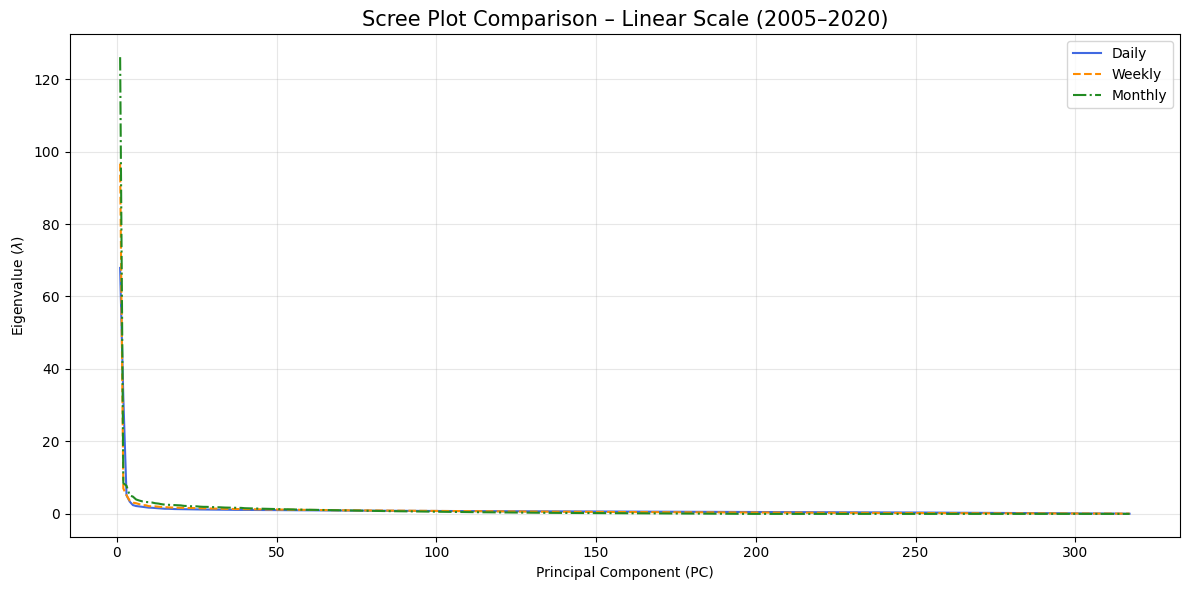

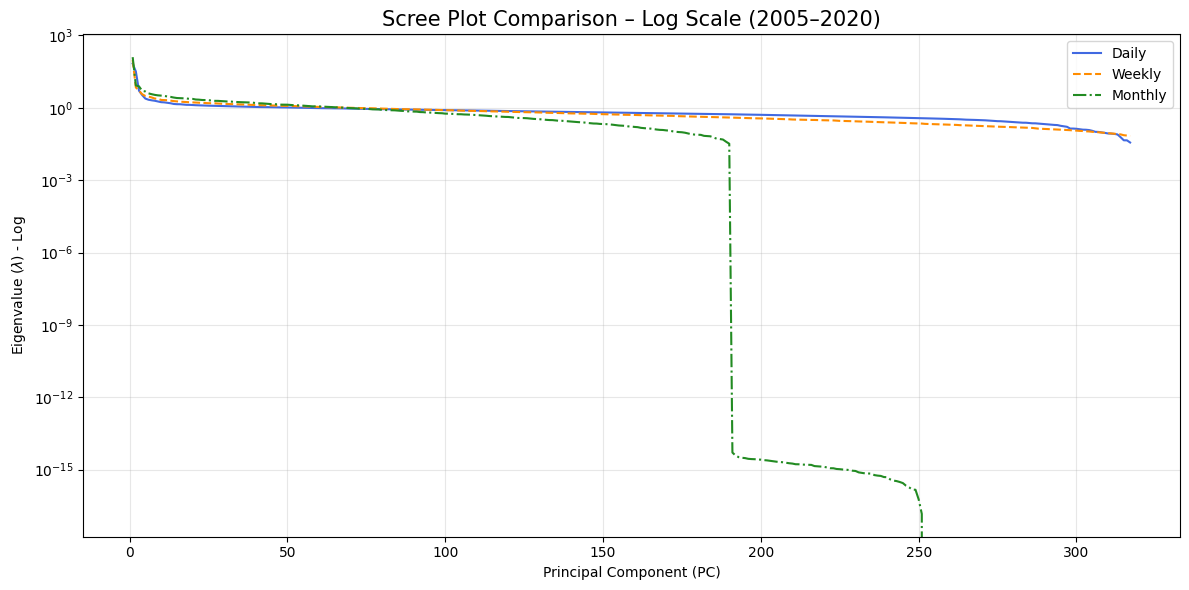

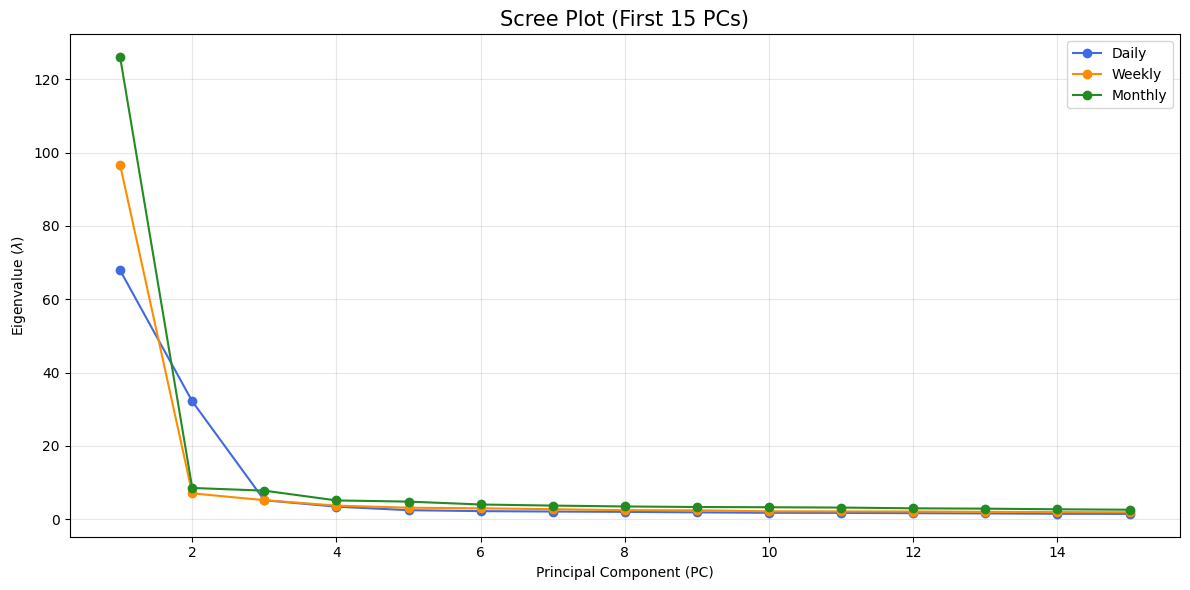

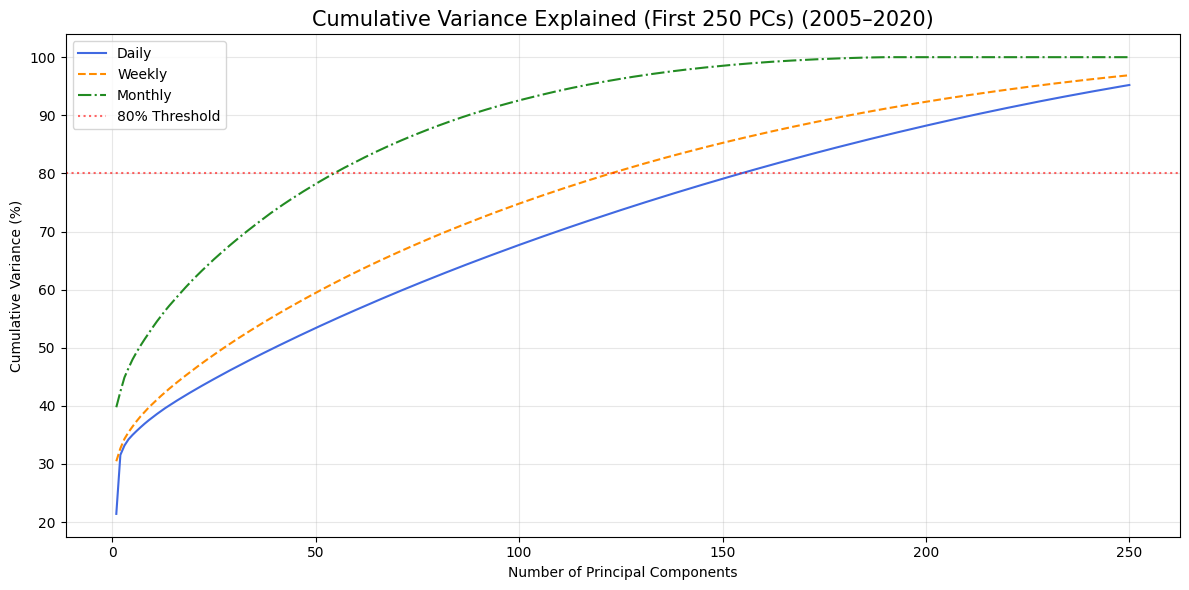

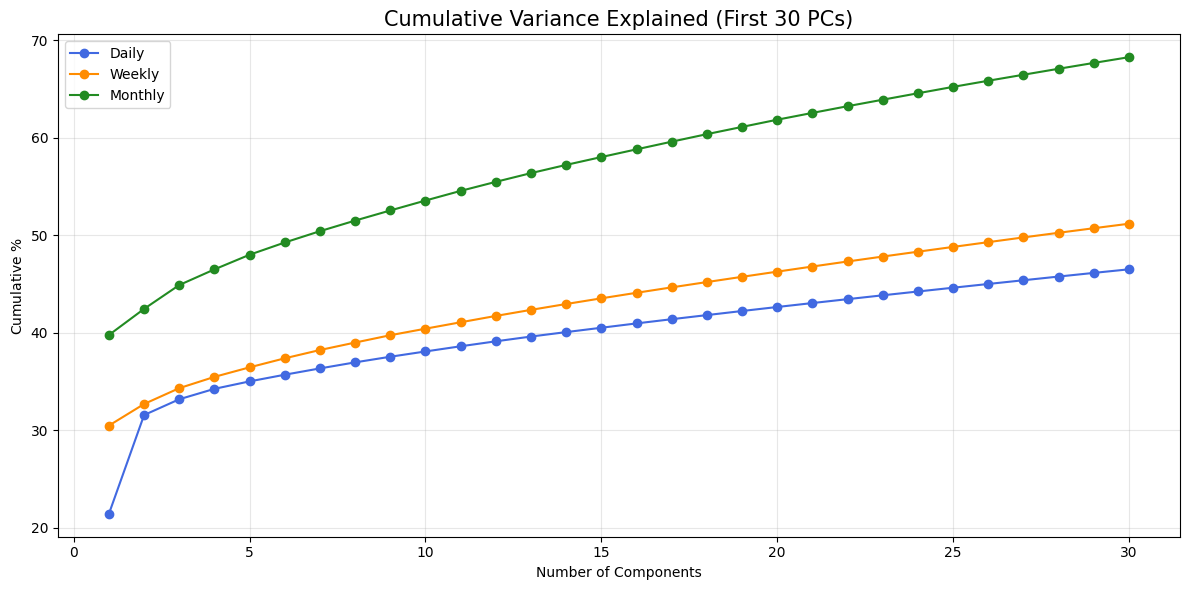

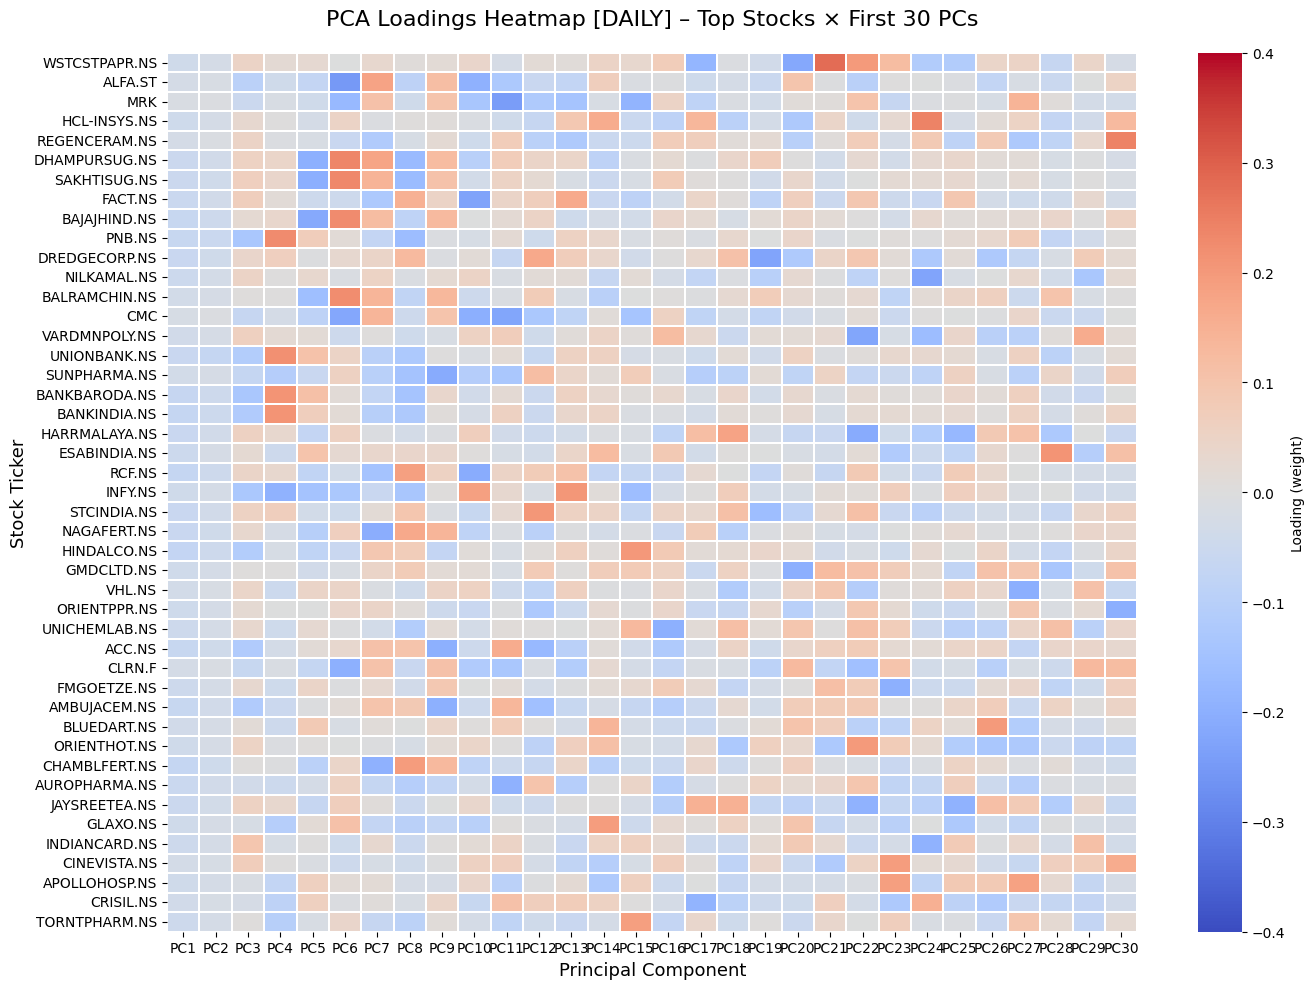

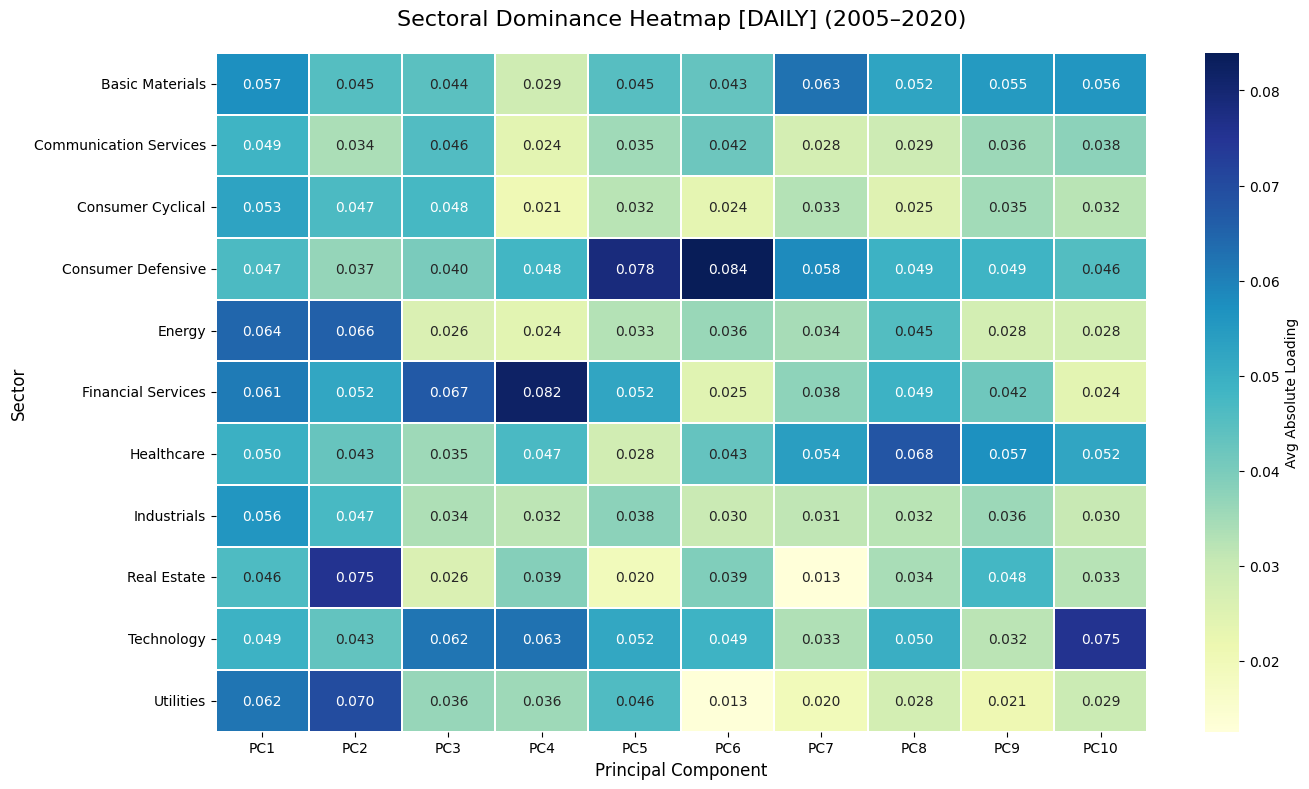

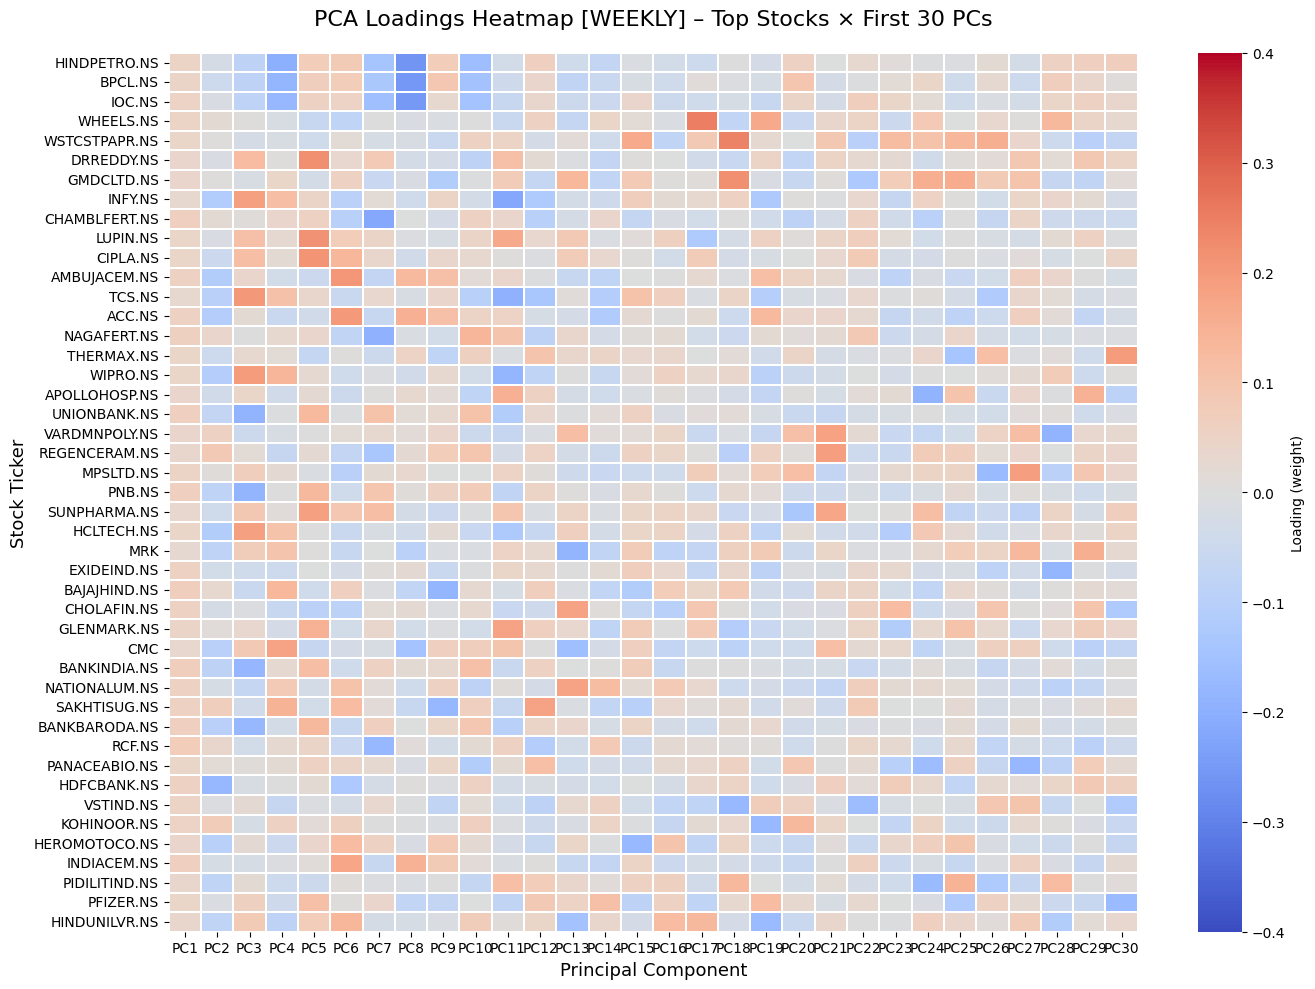

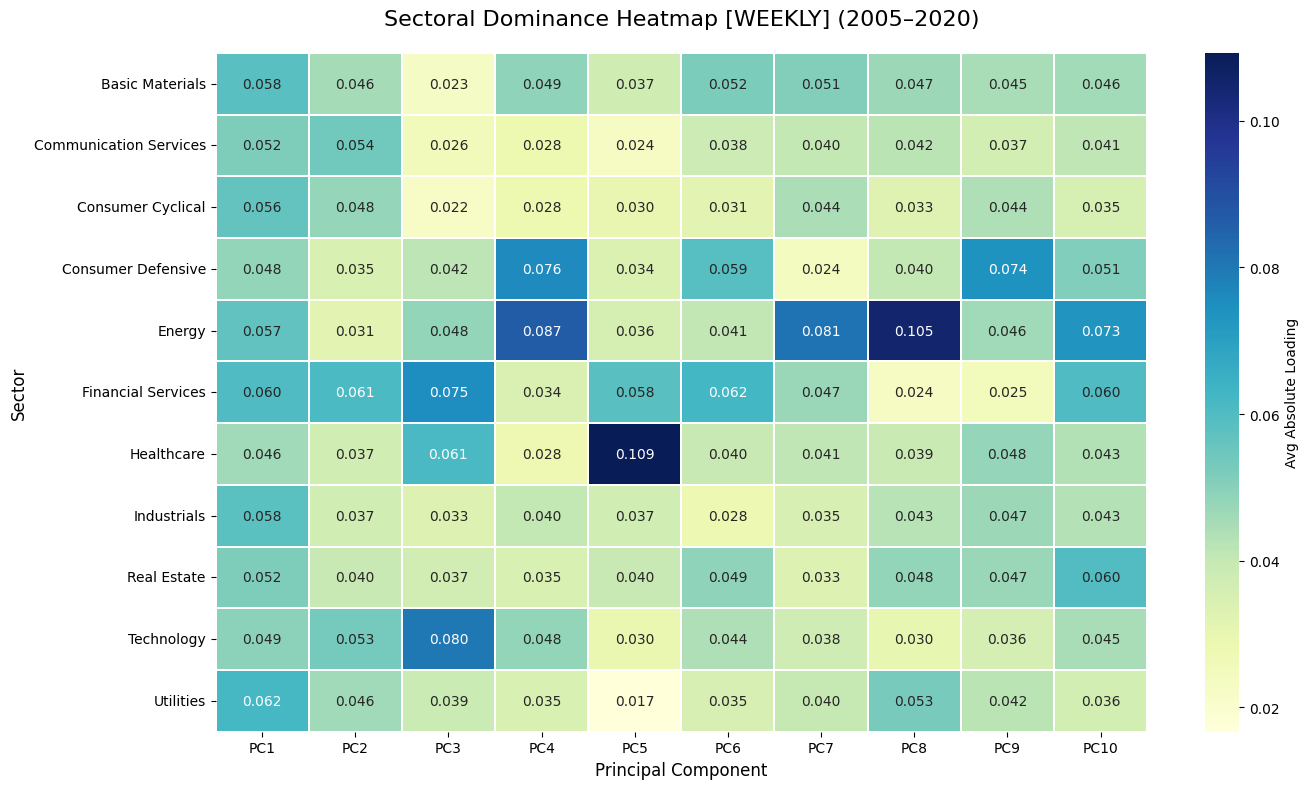

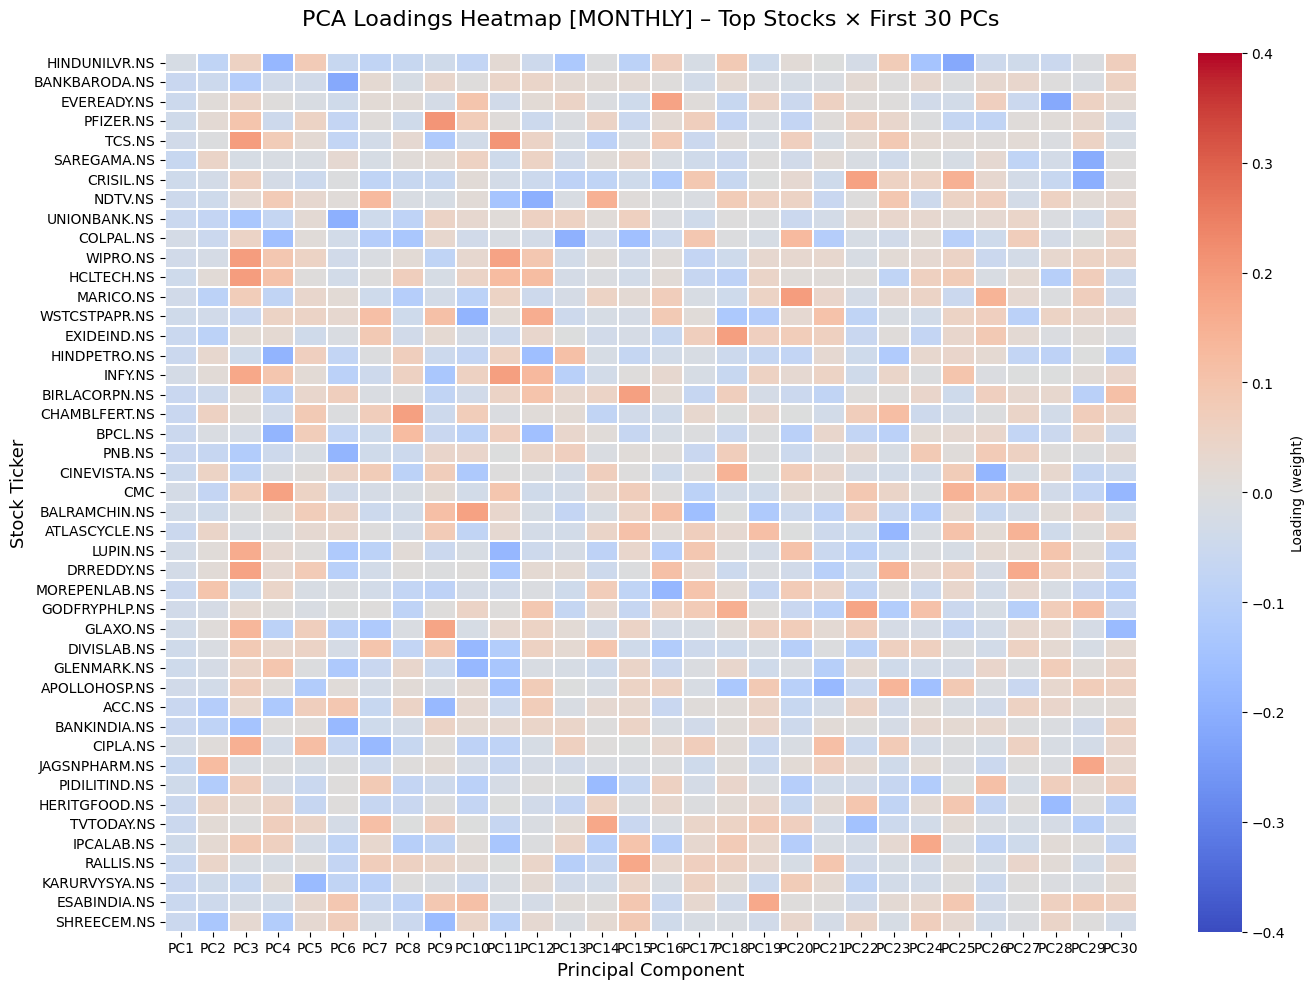

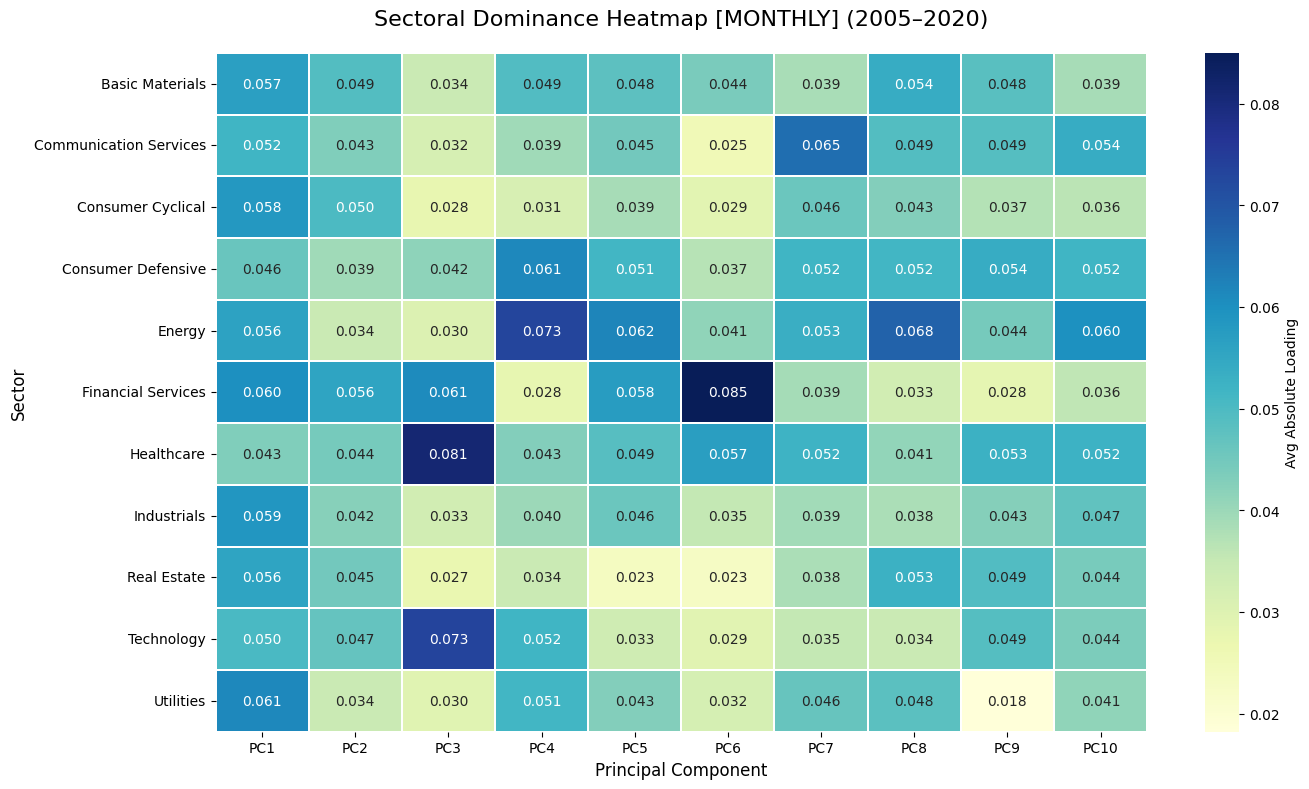


Multi-Frequency Analysis Complete for 2005–2020.


In [53]:
run_pca_analysis(2005, 2020)

## Analysis 2005 - 2010


MULTI-FREQUENCY PCA ANALYSIS: 2005 – 2010


############################################# DAILY ANALYSIS #############################################

[1] DATASET STRUCTURE (DAILY):
Total Rows (Trading Periods): 1555
Total Columns (Stocks):       317
Full Data Shape: (1555, 317)


,3MINDIA.NS,ABB.NS,ACC.NS,ABAN.NS,ADANIENT.NS,ADOR.NS,AKSHOPTFBR.NS,AKZOINDIA.NS,ALEMBICLTD.NS,ALFA.ST,...,M&M.NS,MRPL.NS,NAGAFERT.NS,ONGC.NS,PGHH.NS,RCF.NS,SCI.NS,STCINDIA.NS,TFCILTD.NS,ZENSARTECH.NS
Date,,,,,,,,,,,,,,,,,,,,,
2005-01-04,-1.045153,-0.220289,1.530818,0.453636,-0.326478,-0.103779,3.113234,2.764681,-0.048195,-0.281542,...,-0.215846,0.759237,-0.338491,-0.219254,-2.334551,2.078960,-0.051894,-0.572065,-0.451890,-0.532451
2005-01-05,-1.902033,-0.065664,-0.452236,0.244080,-1.143972,-1.961358,2.688584,-1.987020,-0.319983,-0.031566,...,-0.968851,-2.634652,-2.388357,-1.740664,-0.115923,-3.011956,-1.597574,-1.910334,-0.527095,-0.578233
2005-01-06,-0.034665,-0.546096,-0.816383,-0.649713,-0.444962,-2.036638,0.717899,-0.764302,-0.776786,-0.031566,...,-0.712437,-0.842935,-0.870797,-0.722890,-1.425861,-0.726895,-1.205609,-1.275409,-0.812103,0.191266
2005-01-07,0.988511,0.062618,1.073700,0.022911,0.158298,2.084353,0.939135,2.113761,1.391686,0.467241,...,-0.295974,0.594909,1.499698,0.351133,0.863837,1.081532,0.251431,0.200170,0.199489,-0.323231
2005-01-10,-0.499073,-0.190306,-0.530461,0.188602,0.161624,-0.095593,1.038613,-0.104571,0.370409,-0.031566,...,-0.444497,0.003862,1.301665,-0.264897,0.093236,0.505464,-0.715330,-0.112852,0.266299,-0.215429



[2] TOP 10 EIGENVALUES & VARIANCE EXPLAINED (DAILY):


,Component,Eigenvalue ($\lambda$),\% Variance Explained,Cumulative Variance ($\%$)
0,PC1,123.704357,26.782212,26.782212
1,PC2,69.153546,14.971865,41.754077
2,PC3,7.708208,1.668841,43.422917
3,PC4,3.905458,0.845539,44.268456
4,PC5,3.682167,0.797196,45.065651
5,PC6,3.265782,0.707048,45.772699
6,PC7,3.121668,0.675847,46.448546
7,PC8,2.846782,0.616333,47.064879
8,PC9,2.778391,0.601527,47.666405
9,PC10,2.730323,0.591120,48.257525



[3] VARIANCE THRESHOLD SUMMARY:


...


[4] EIGENVECTORS (LOADINGS) - TOP 10 PCs (First 10 Stocks shown):


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10
3MINDIA.NS,-0.058826,-0.075538,0.071312,-0.006817,-0.006223,0.113507,-0.010547,0.006636,-0.058816,0.018153
ABB.NS,-0.037732,-0.082870,-0.022307,-0.035951,0.078968,-0.003706,-0.031793,0.123806,0.099336,0.047186
ACC.NS,-0.053773,-0.070164,0.066858,-0.116081,-0.016760,-0.167758,-0.060778,0.009223,-0.045507,-0.116759
ABAN.NS,-0.062301,-0.077347,-0.023394,0.107237,0.066200,0.049881,-0.117398,-0.069121,0.066388,-0.008421
ADANIENT.NS,-0.036653,0.022587,-0.141649,0.045202,-0.031919,0.049772,0.094378,-0.063989,-0.055993,-0.038470
ADOR.NS,-0.059041,0.072371,0.060724,-0.018238,0.061689,-0.035910,0.010633,0.099313,0.004697,0.005205
AKSHOPTFBR.NS,-0.056599,0.025113,-0.001966,0.002860,0.019634,0.043786,-0.028606,-0.013570,0.015660,-0.038178
AKZOINDIA.NS,-0.029688,-0.001909,0.030227,0.011843,-0.069840,0.013289,-0.132668,0.004775,-0.023205,0.034201
ALEMBICLTD.NS,-0.038016,-0.005084,0.008460,-0.038212,0.024202,0.065575,-0.024537,-0.005743,-0.037398,-0.024360
ALFA.ST,-0.031879,-0.112752,0.049310,0.051844,0.044874,0.178807,-0.051322,-0.007091,-0.058940,-0.168230



[5] EIGENVECTOR SUMMARY STATISTICS (TOP 10 PCs):


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10
mean,-0.054999,-0.000801,0.002542,-0.001102,-0.001573,0.001053,0.000622,0.001961,-0.000091,0.000080
std,0.011406,0.056249,0.056197,0.056244,0.056232,0.056245,0.056251,0.056220,0.056254,0.056254
min,-0.086740,-0.150267,-0.157575,-0.195934,-0.140974,-0.242672,-0.175517,-0.146864,-0.182523,-0.168230
max,-0.011880,0.125046,0.187652,0.127383,0.177276,0.196434,0.177844,0.153103,0.231403,0.229692



[6] DOMINANT SECTORS (TOP 3 PCs):
 - PC1: Industrials               | Avg Abs Loading: 0.0586
 - PC2: Energy                    | Avg Abs Loading: 0.0583
 - PC3: Healthcare                | Avg Abs Loading: 0.0632


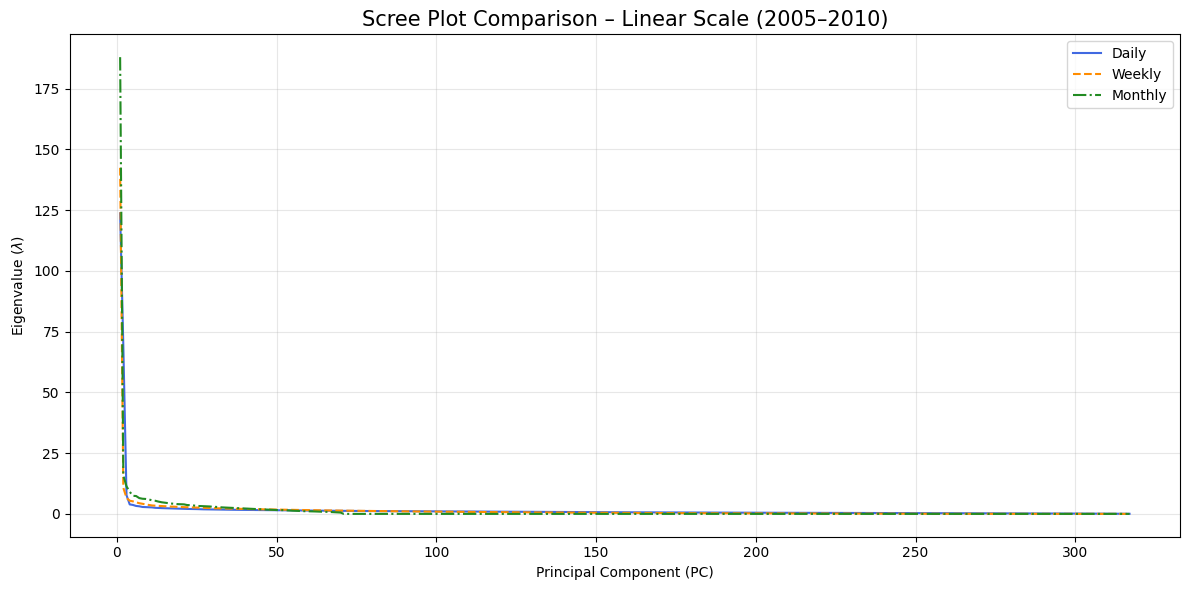

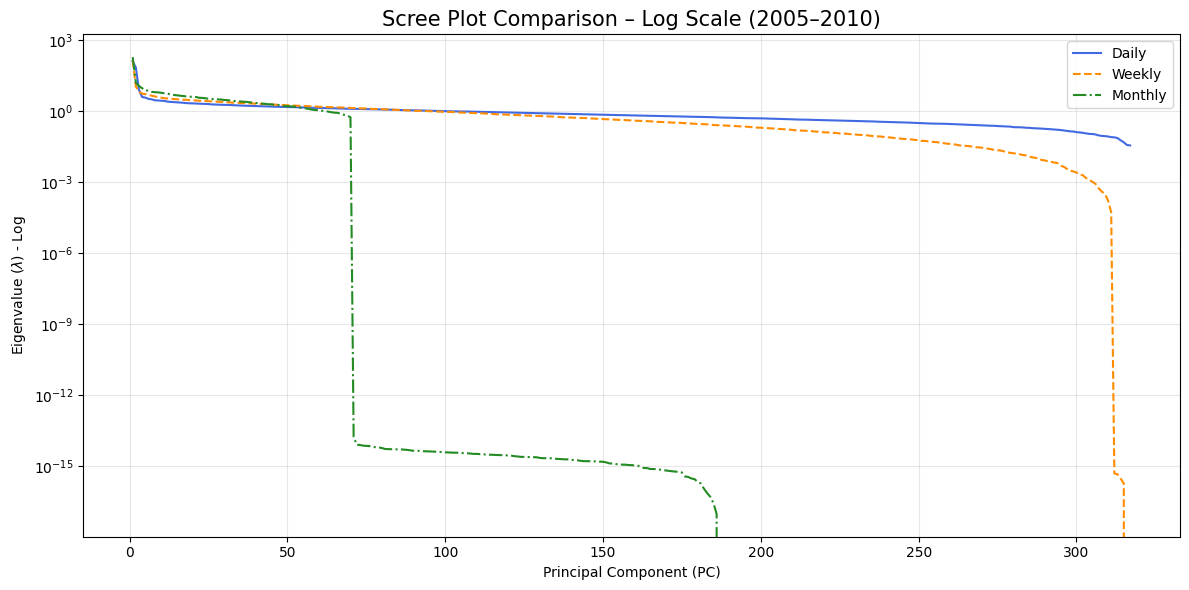

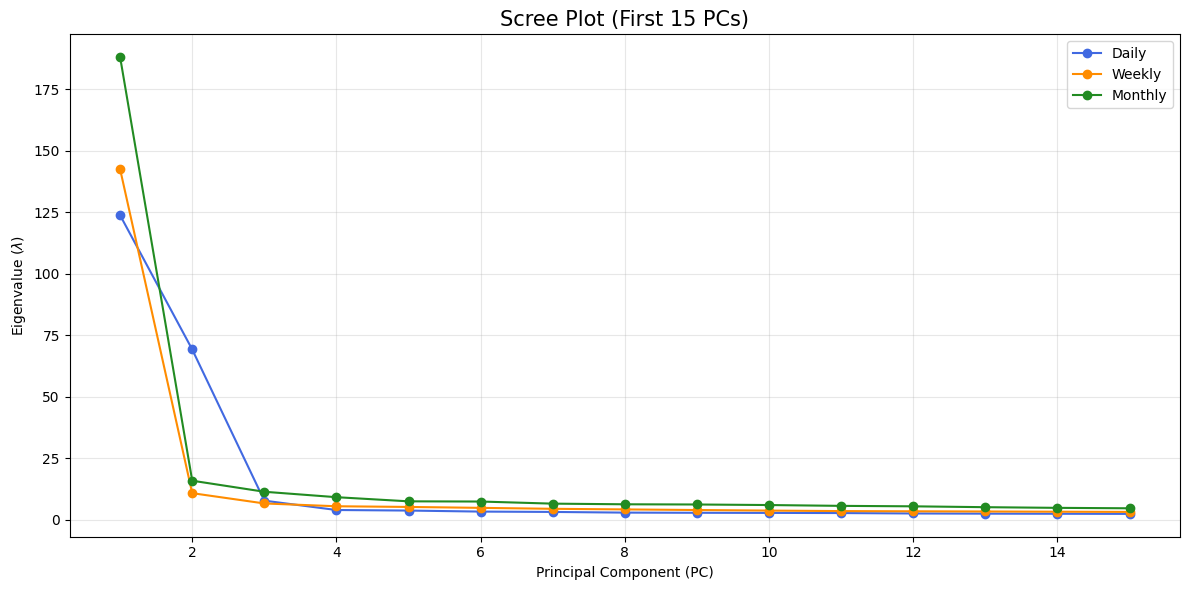

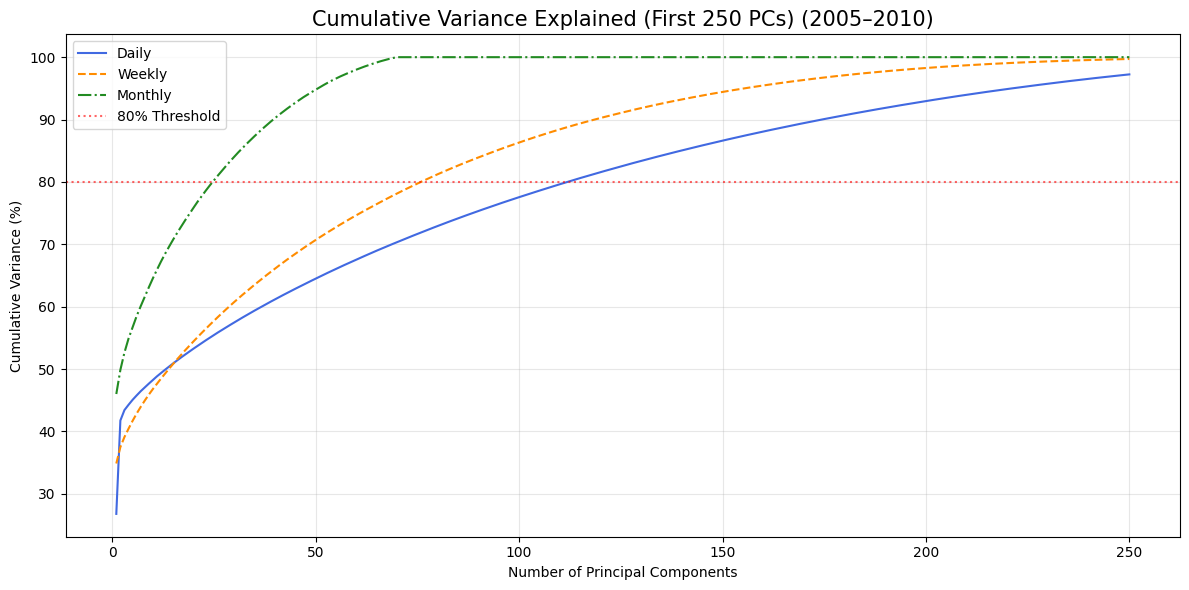

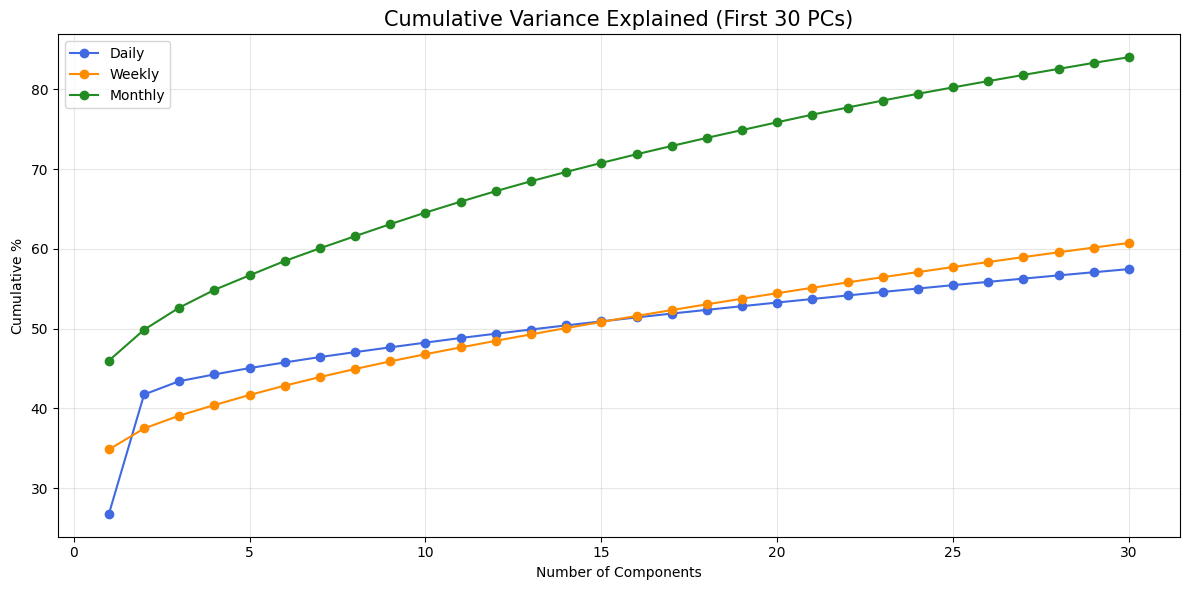

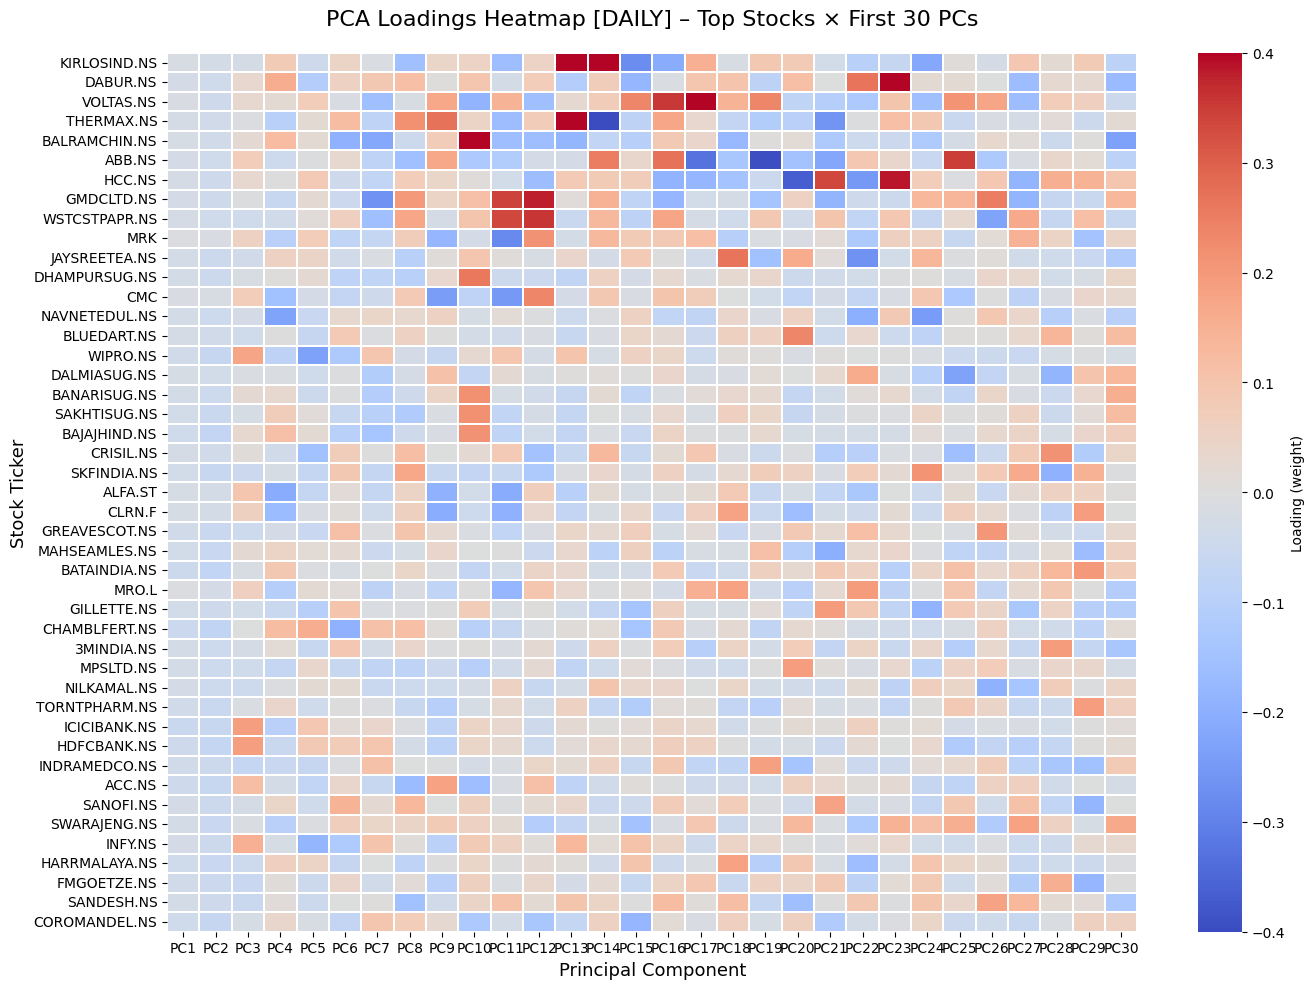

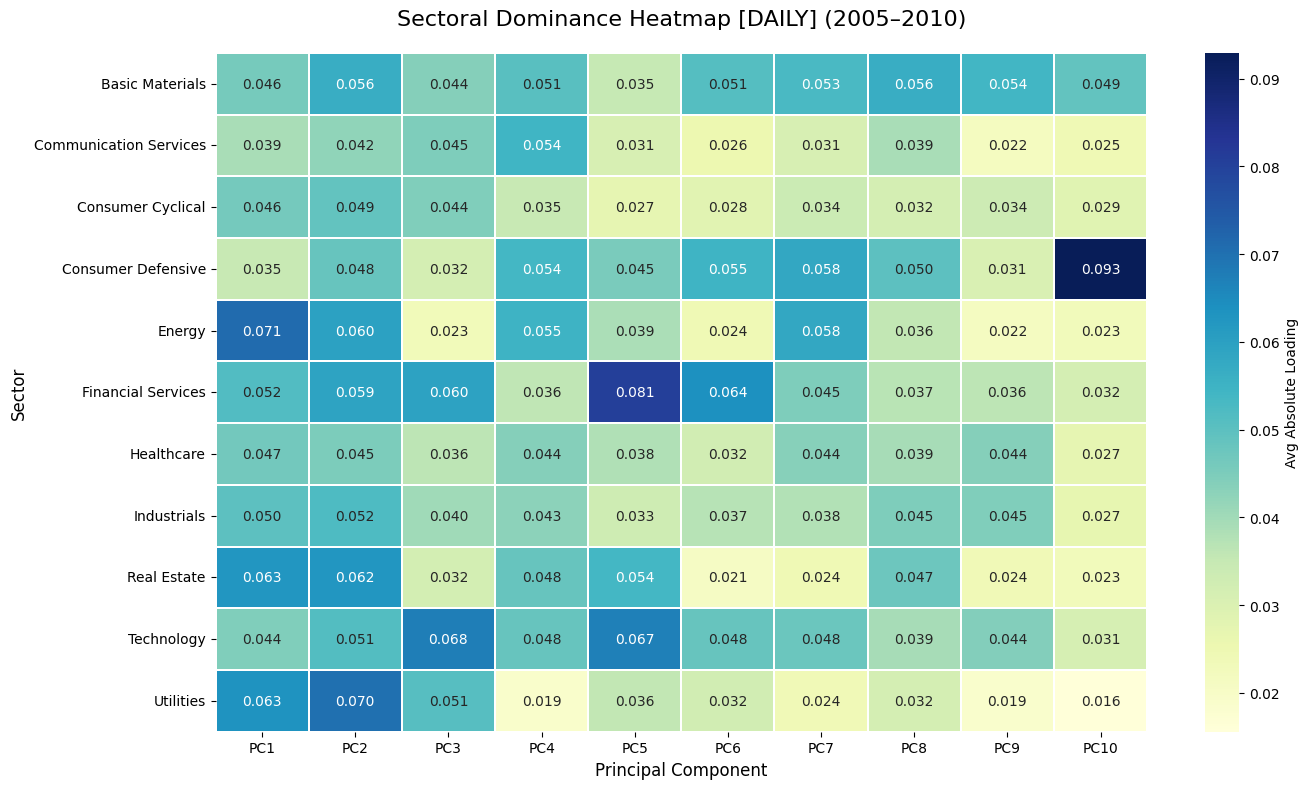

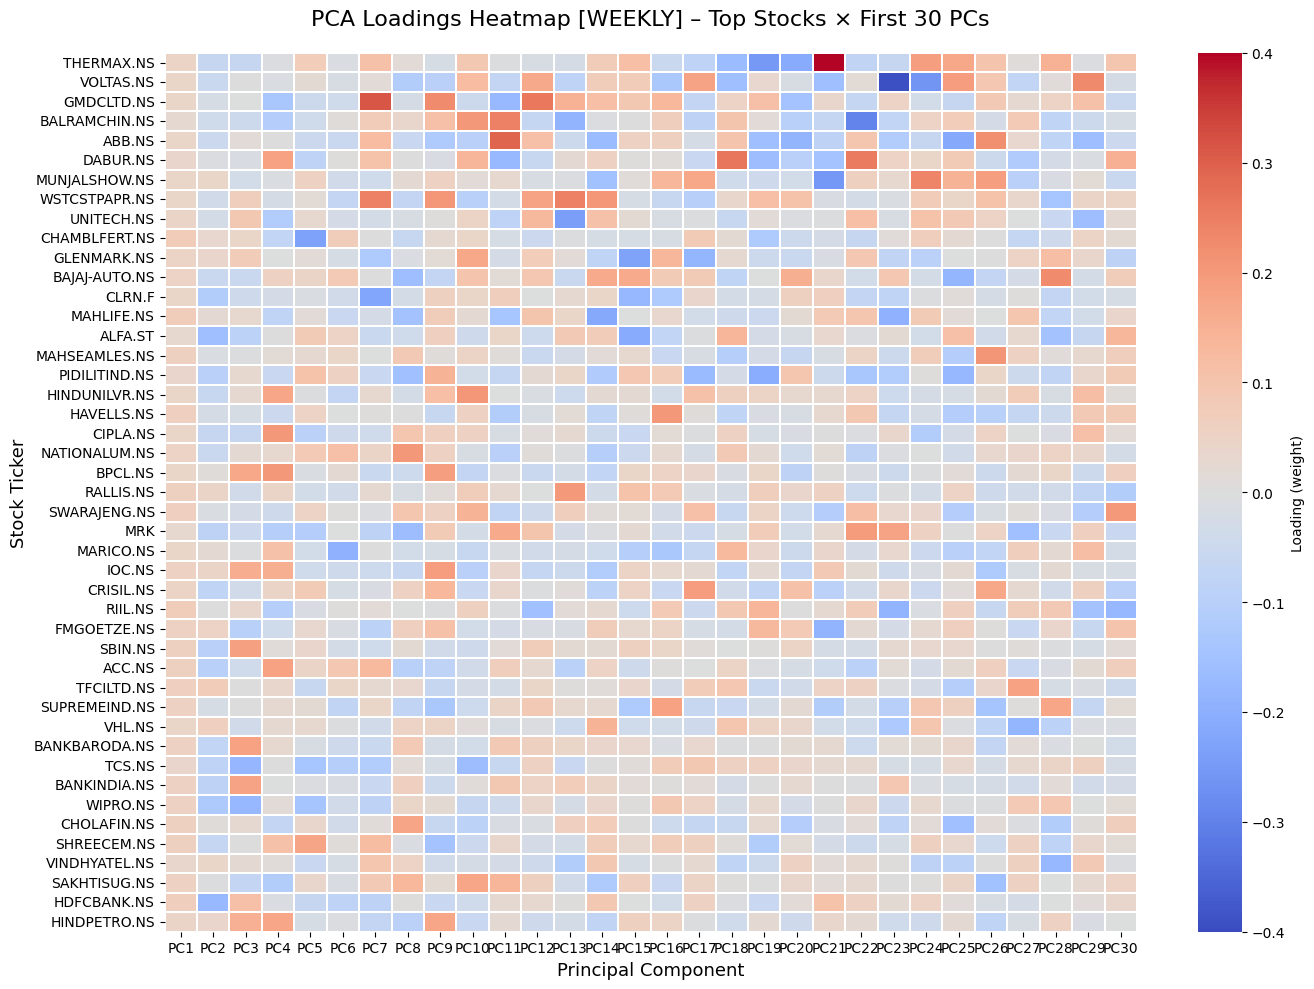

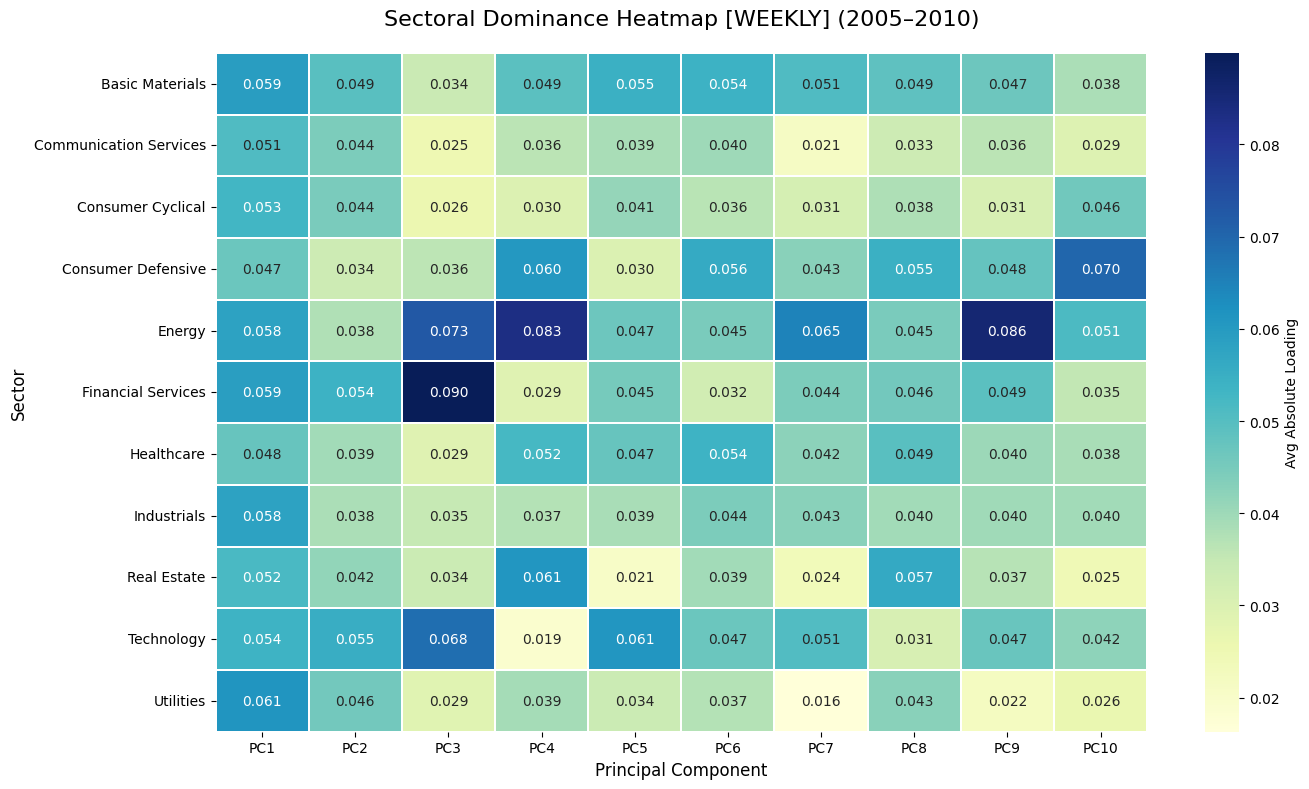

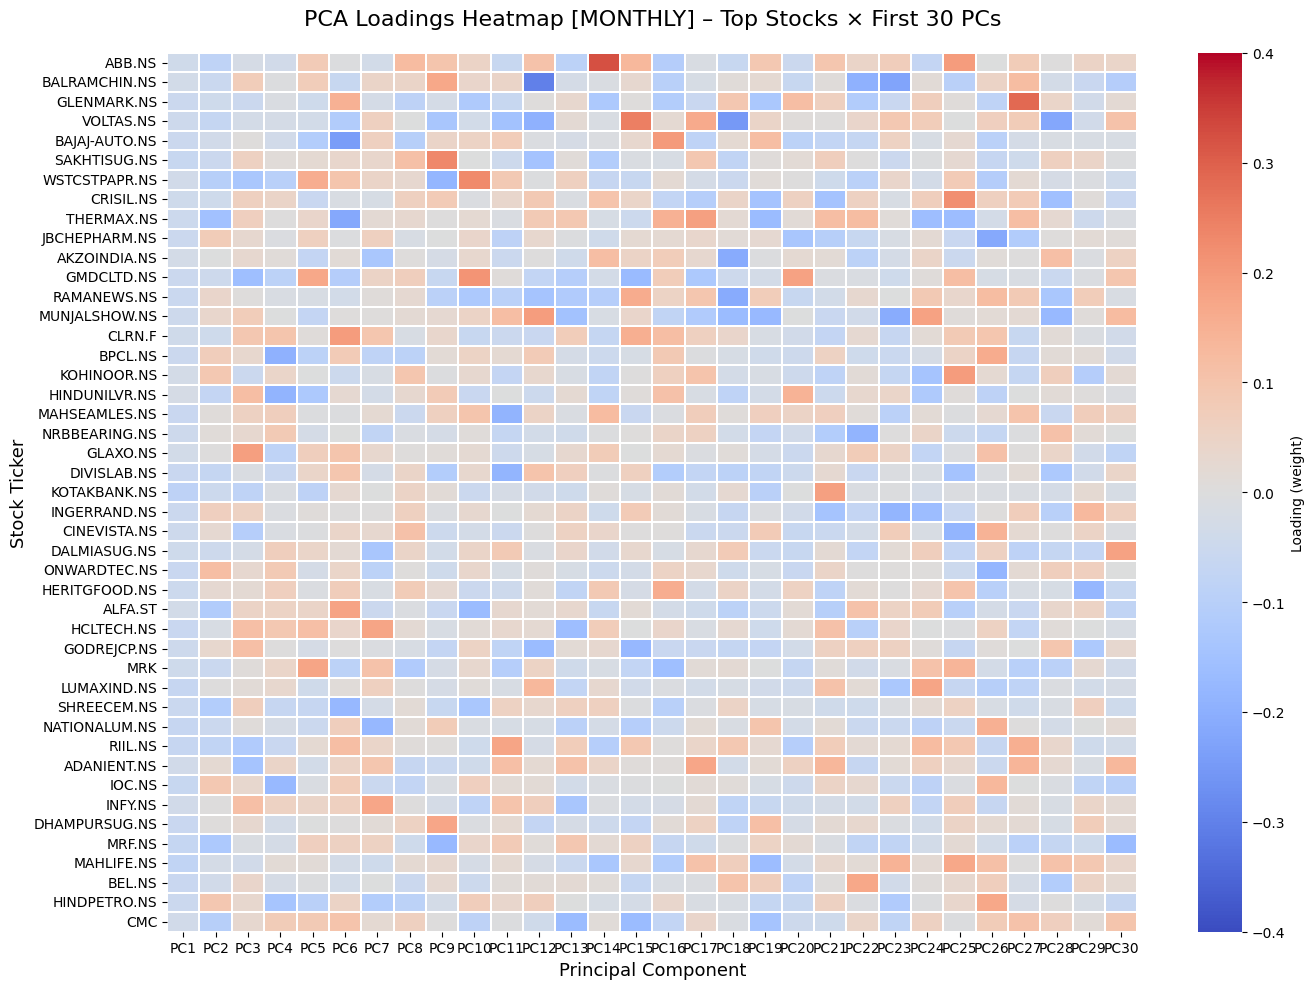

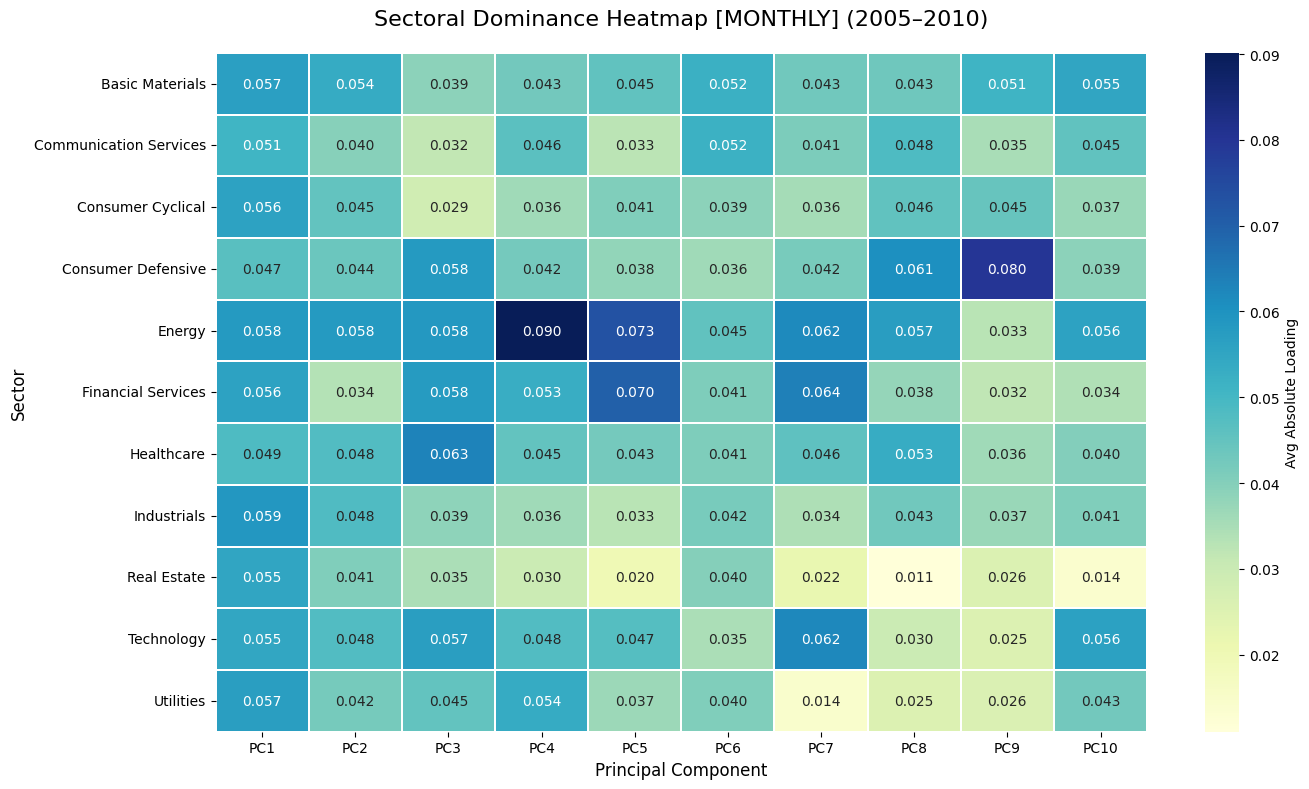


Multi-Frequency Analysis Complete for 2005–2010.


In [54]:
run_pca_analysis(2005, 2010)

## Analysis 2010 - 2015


MULTI-FREQUENCY PCA ANALYSIS: 2010 – 2015


############################################# DAILY ANALYSIS #############################################

[1] DATASET STRUCTURE (DAILY):
Total Rows (Trading Periods): 1558
Total Columns (Stocks):       317
Full Data Shape: (1558, 317)


,3MINDIA.NS,ABB.NS,ACC.NS,ABAN.NS,ADANIENT.NS,ADOR.NS,AKSHOPTFBR.NS,AKZOINDIA.NS,ALEMBICLTD.NS,ALFA.ST,...,M&M.NS,MRPL.NS,NAGAFERT.NS,ONGC.NS,PGHH.NS,RCF.NS,SCI.NS,STCINDIA.NS,TFCILTD.NS,ZENSARTECH.NS
Date,,,,,,,,,,,,,,,,,,,,,
2010-01-04,-0.249883,-0.059841,1.248482,0.710851,0.509655,0.112944,-0.679673,0.190486,0.047733,0.575579,...,0.851122,0.321271,1.274202,0.179087,-0.530478,1.969496,0.068477,0.266698,0.175177,0.323325
2010-01-05,-0.049269,-0.103801,-0.747398,0.489041,0.672157,0.006968,-0.069301,0.094329,0.039639,-0.188380,...,0.696149,0.889565,-0.094706,0.804411,0.665312,0.593949,2.889032,-0.397202,0.128612,-0.431299
2010-01-06,-0.333327,-0.016031,0.331924,-0.131931,2.857011,0.188728,1.244878,-0.702931,0.469921,-0.031566,...,0.911687,1.375306,0.765631,0.578895,-1.100717,0.666971,0.456806,-0.402311,-0.138745,0.082327
2010-01-07,0.383986,0.707698,0.323587,2.154019,-1.321876,-0.579374,-0.066387,0.208270,0.382378,1.566851,...,-0.783176,0.049505,-0.143029,0.041869,0.618194,-0.648561,0.018822,0.176588,0.914026,0.028166
2010-01-08,-0.163253,0.503341,-0.098263,0.880372,0.355693,-0.206321,2.123271,-0.213925,-0.595384,0.423585,...,-0.020464,-0.224902,-0.244702,-0.356600,-0.885394,0.187788,0.093271,2.959719,-0.307183,-0.286238



[2] TOP 10 EIGENVALUES & VARIANCE EXPLAINED (DAILY):


,Component,Eigenvalue ($\lambda$),\% Variance Explained,Cumulative Variance ($\%$)
0,PC1,41.320965,18.890963,18.890963
1,PC2,4.224140,1.931176,20.822139
2,PC3,2.796502,1.278494,22.100633
3,PC4,1.968295,0.899858,23.000491
4,PC5,1.867289,0.853680,23.854172
5,PC6,1.800546,0.823167,24.677339
6,PC7,1.750889,0.800465,25.477803
7,PC8,1.710678,0.782081,26.259885
8,PC9,1.633175,0.746649,27.006534
9,PC10,1.616948,0.739230,27.745764



[3] VARIANCE THRESHOLD SUMMARY:


...


[4] EIGENVECTORS (LOADINGS) - TOP 10 PCs (First 10 Stocks shown):


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10
3MINDIA.NS,0.037035,0.007136,-0.091457,0.014154,0.022036,-0.008179,0.058238,-0.032620,0.009681,-0.049429
ABB.NS,0.051144,0.033198,0.002095,0.018304,0.009979,0.035442,0.005117,0.004924,0.018024,0.016864
ACC.NS,0.052777,0.123068,-0.040725,-0.004106,-0.075132,0.063306,0.001850,-0.004548,0.004379,0.027500
ABAN.NS,0.060008,-0.004513,0.019495,0.099818,-0.035043,0.076112,0.016659,-0.026901,0.028948,-0.029600
ADANIENT.NS,0.055010,0.063767,0.038654,0.056735,0.050830,-0.015835,0.124673,-0.031737,0.049416,0.009628
ADOR.NS,0.073108,-0.012898,-0.003567,-0.046649,0.021667,0.023607,-0.013733,0.046539,-0.038798,-0.032271
AKSHOPTFBR.NS,0.029246,-0.041788,-0.071346,0.003334,-0.017238,0.054960,-0.004356,-0.044404,0.000427,0.042617
AKZOINDIA.NS,0.055618,0.082628,-0.122380,-0.168217,-0.053343,-0.091899,0.014047,-0.021122,0.015568,-0.062727
ALEMBICLTD.NS,0.053747,-0.024457,-0.008787,-0.054080,0.020839,-0.034288,0.013614,0.208975,-0.136161,-0.017919
ALFA.ST,0.030323,-0.011849,-0.043983,0.106042,-0.132140,0.043247,0.047218,0.015227,0.107377,0.057035



[5] EIGENVECTOR SUMMARY STATISTICS (TOP 10 PCs):


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10
mean,0.053325,-0.003012,-0.008989,0.002334,-0.002339,0.001272,-0.000636,-0.001705,-0.000262,0.000487
std,0.017662,0.056173,0.055529,0.056206,0.056206,0.056240,0.056251,0.056228,0.056254,0.056252
min,-0.004451,-0.156107,-0.179927,-0.168217,-0.167839,-0.188365,-0.227586,-0.171767,-0.161650,-0.214969
max,0.093940,0.134506,0.118631,0.230298,0.183708,0.189654,0.147796,0.208975,0.191717,0.186571



[6] DOMINANT SECTORS (TOP 3 PCs):
 - PC1: Financial Services        | Avg Abs Loading: 0.0609
 - PC2: Financial Services        | Avg Abs Loading: 0.0667
 - PC3: Consumer Defensive        | Avg Abs Loading: 0.0687


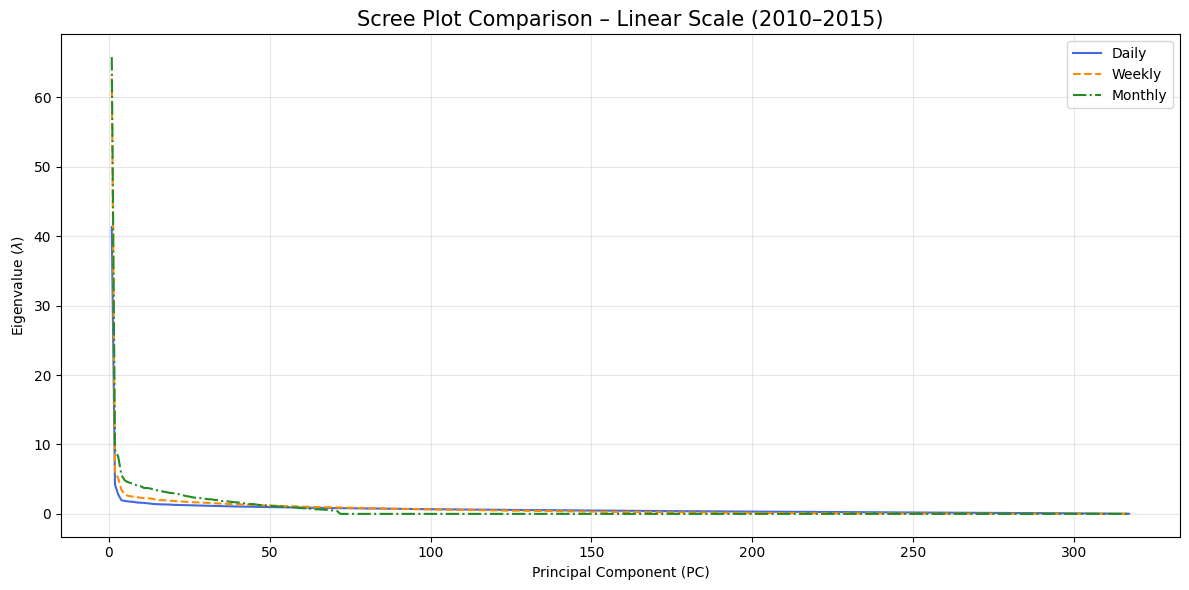

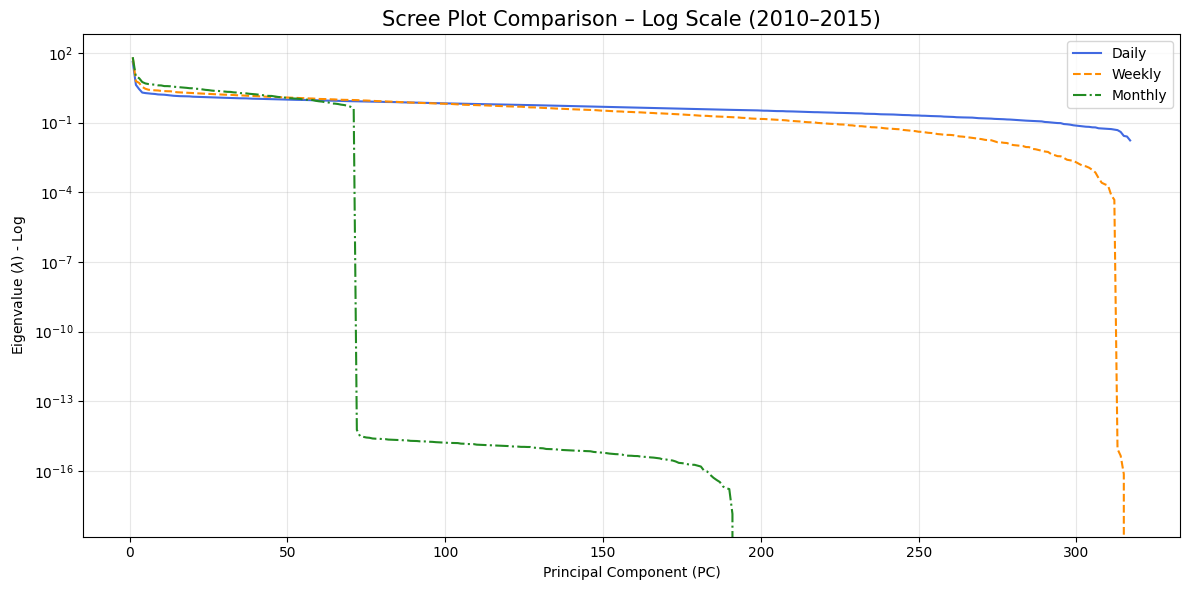

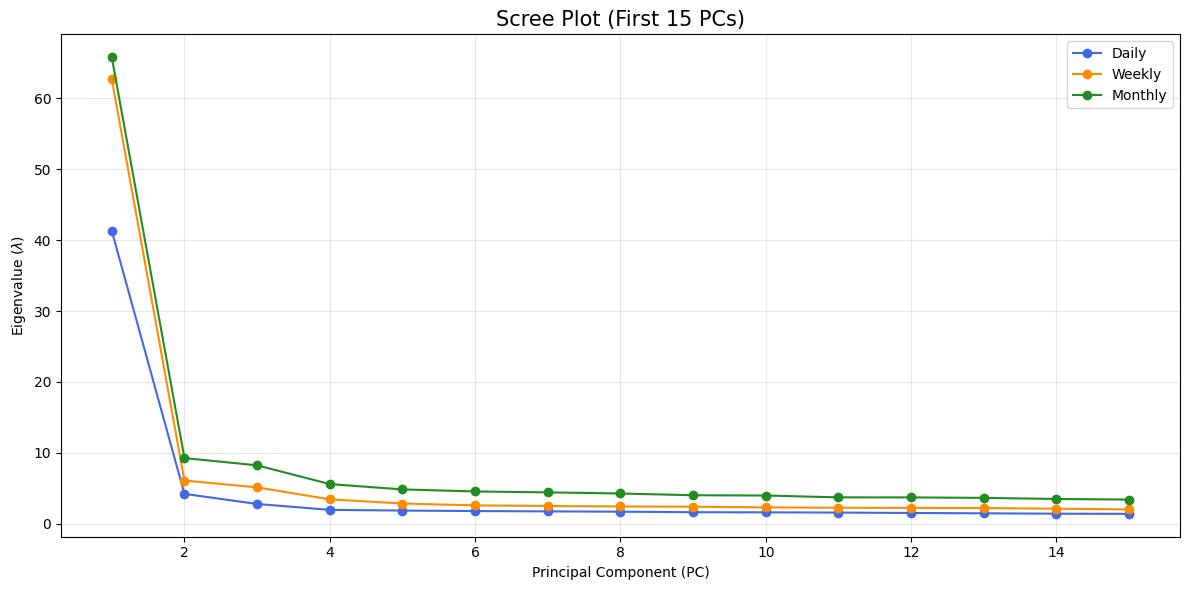

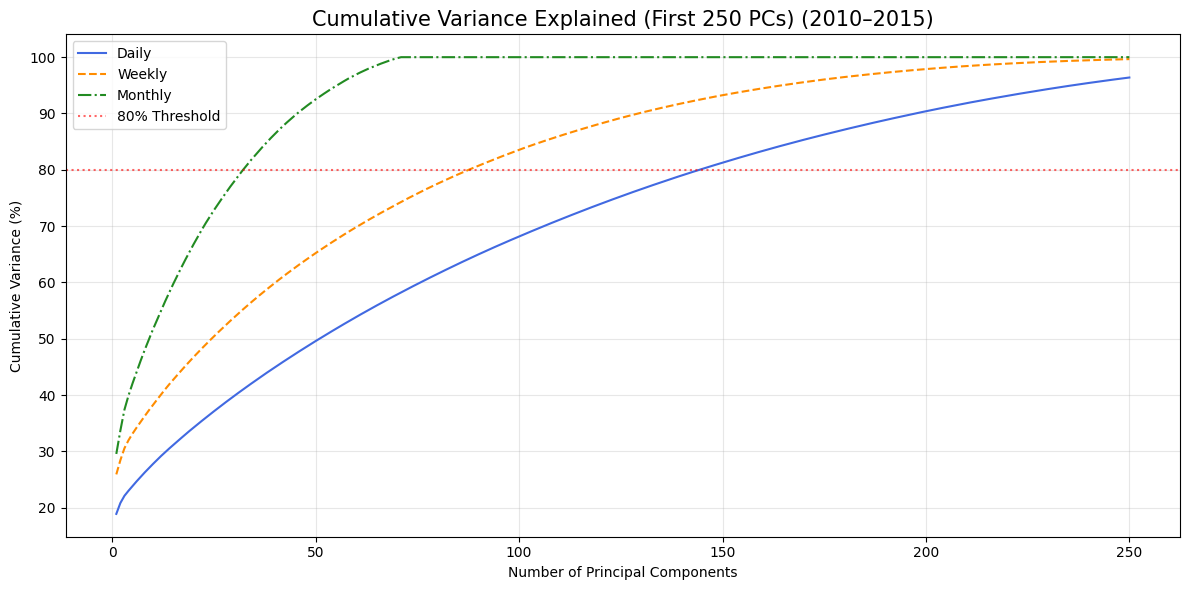

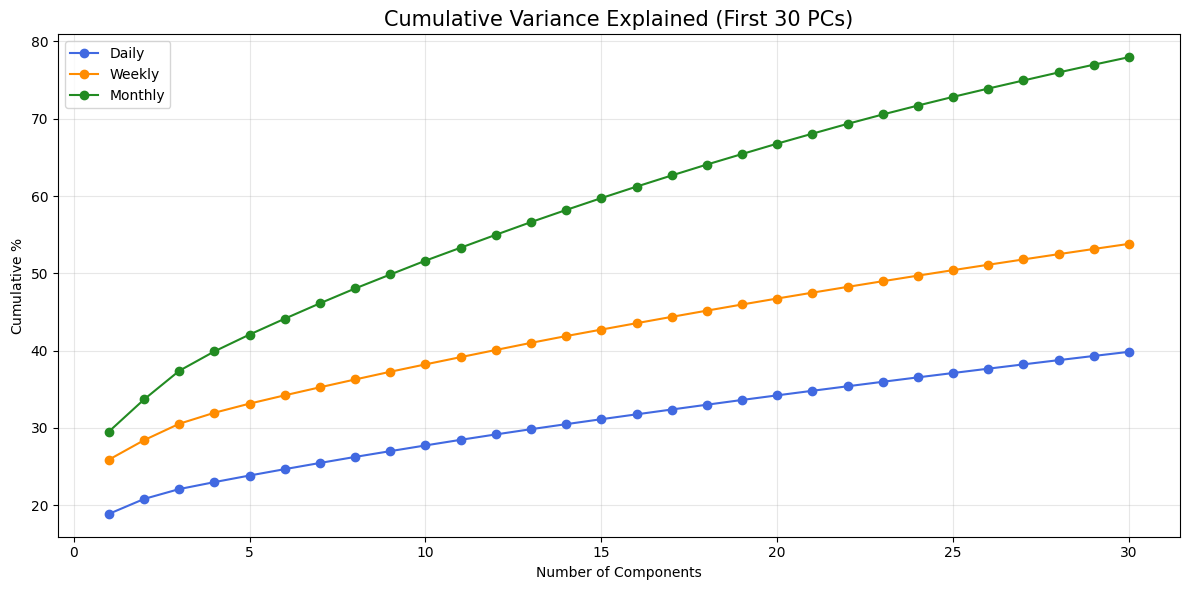

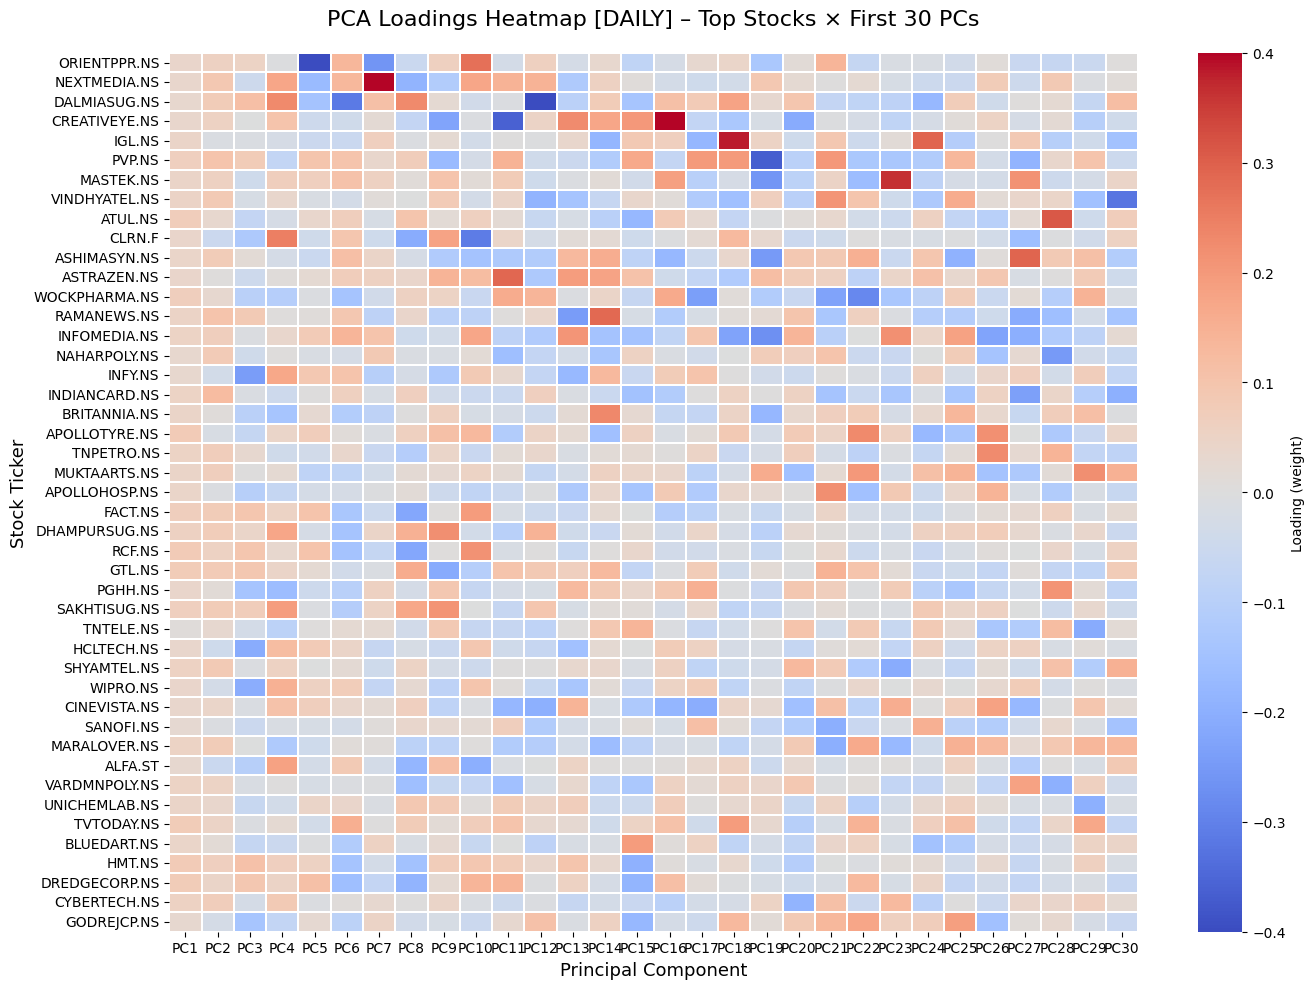

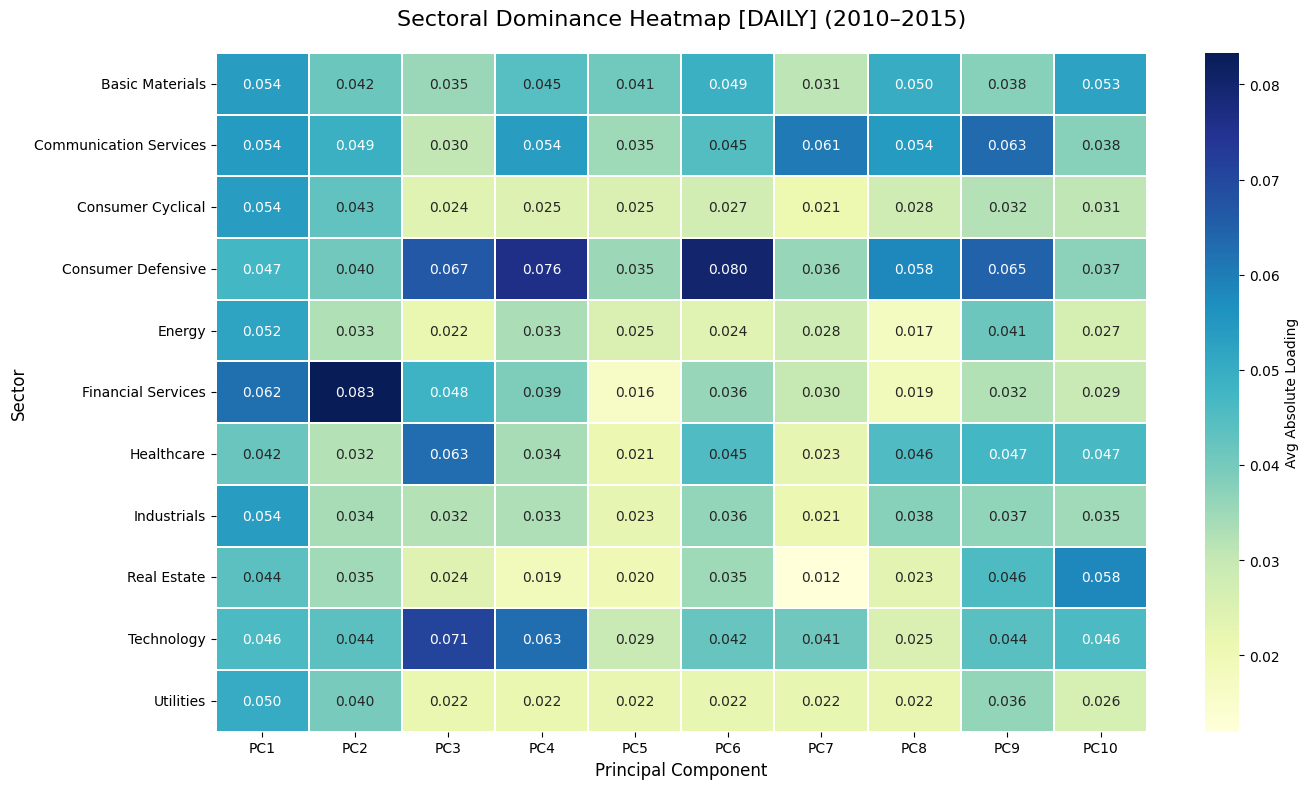

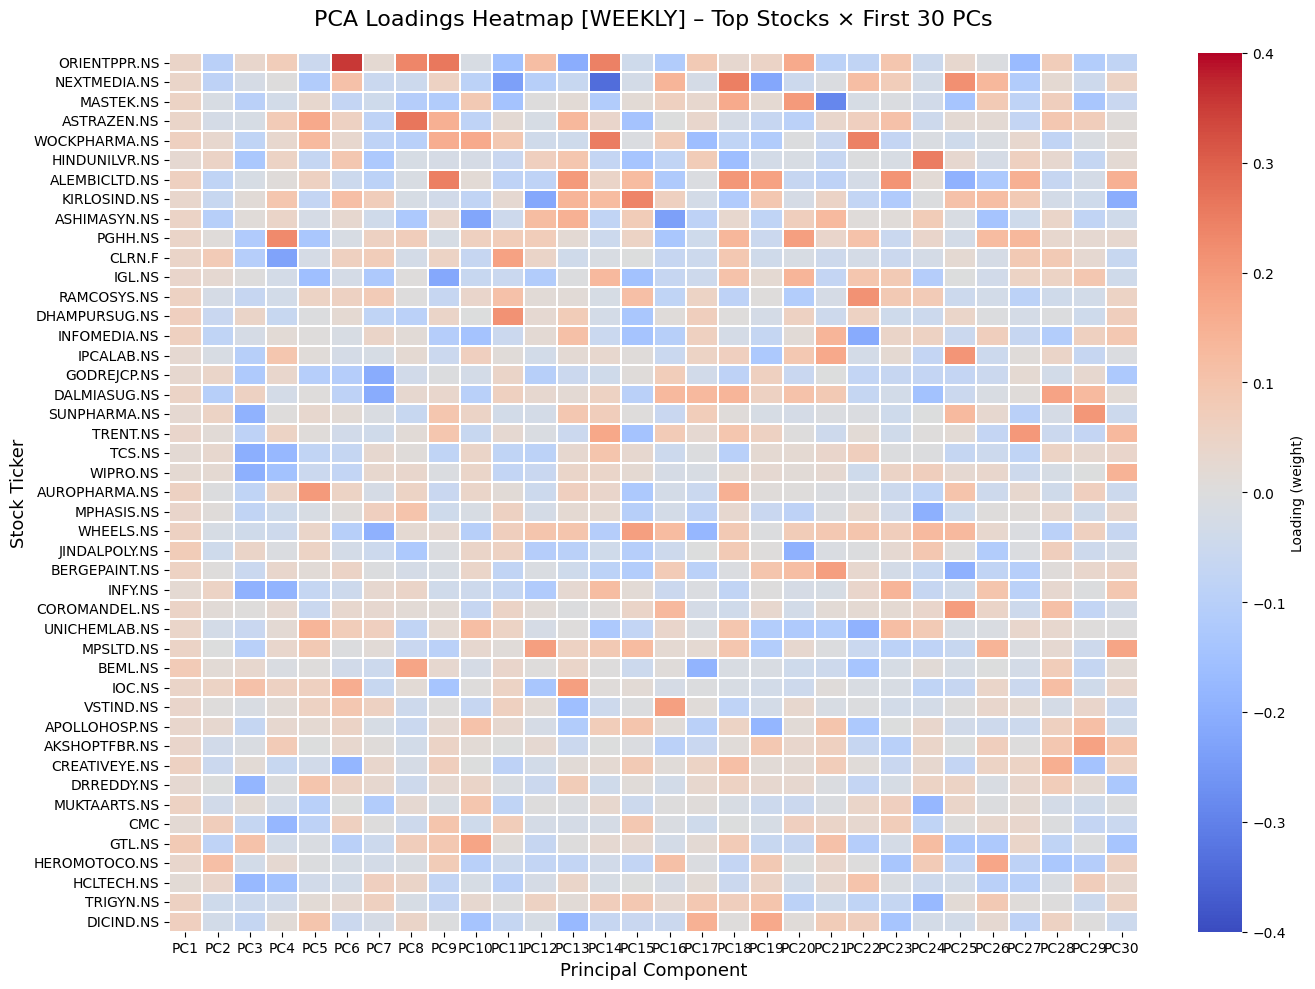

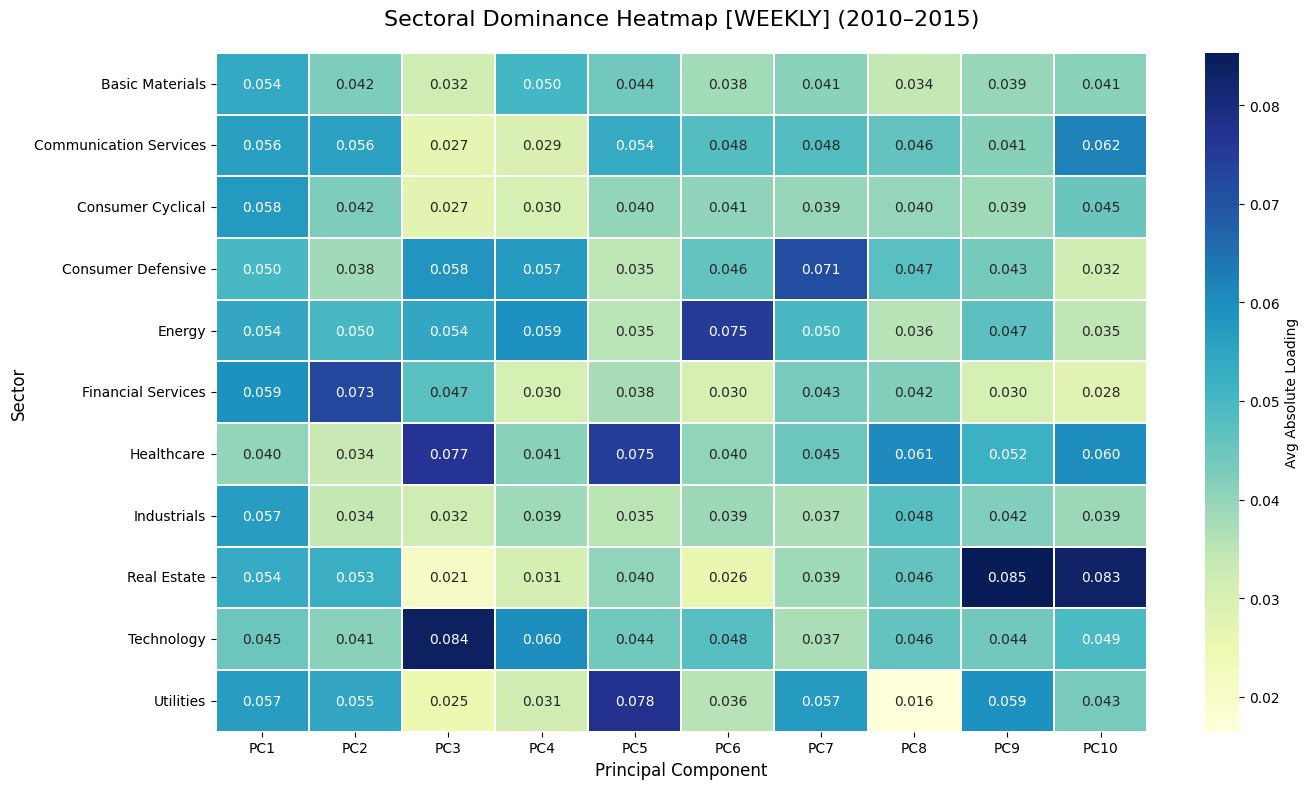

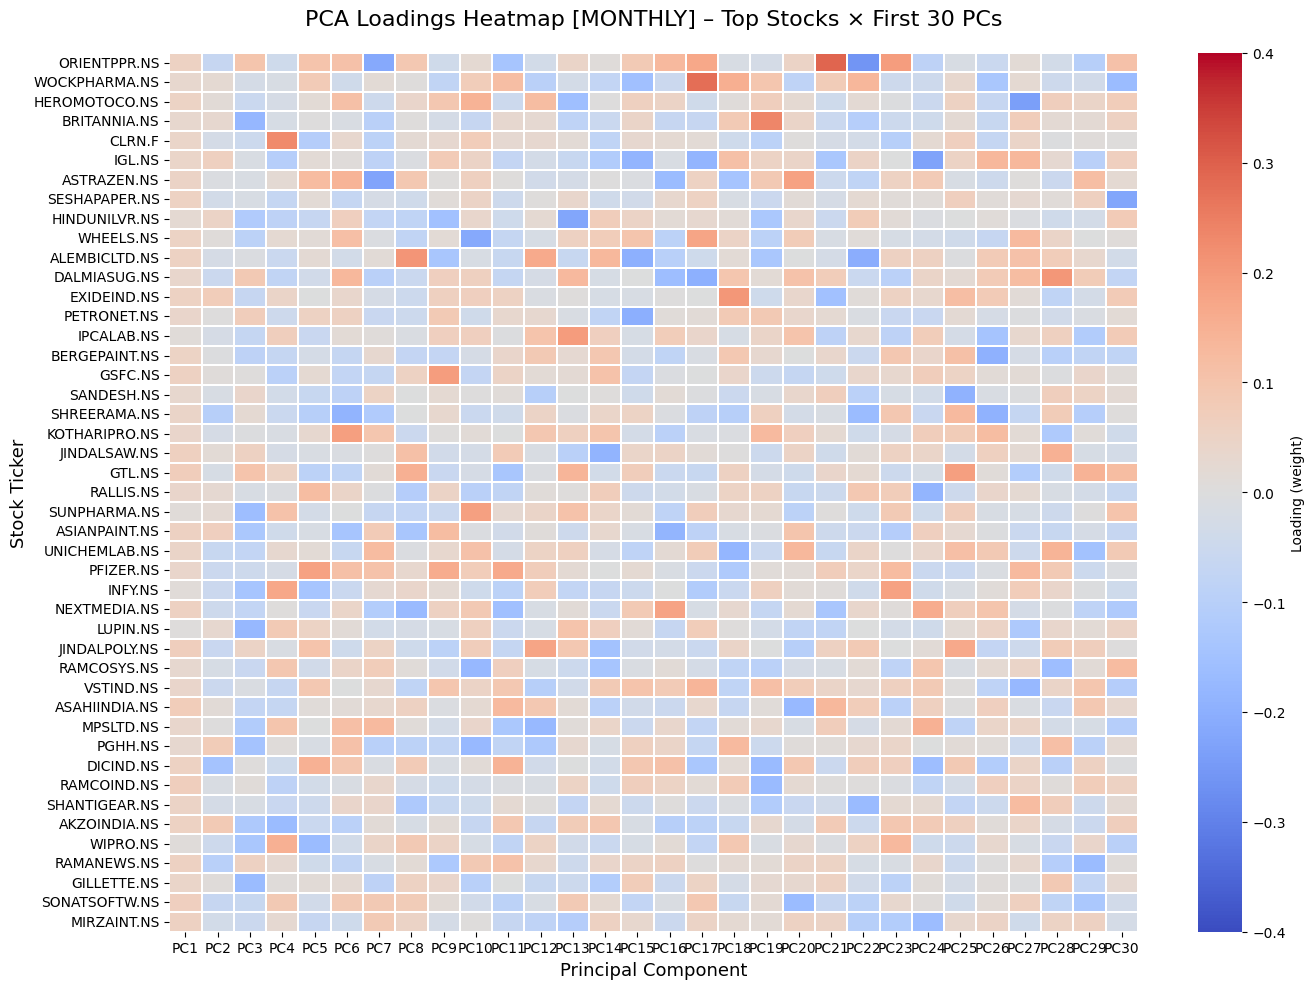

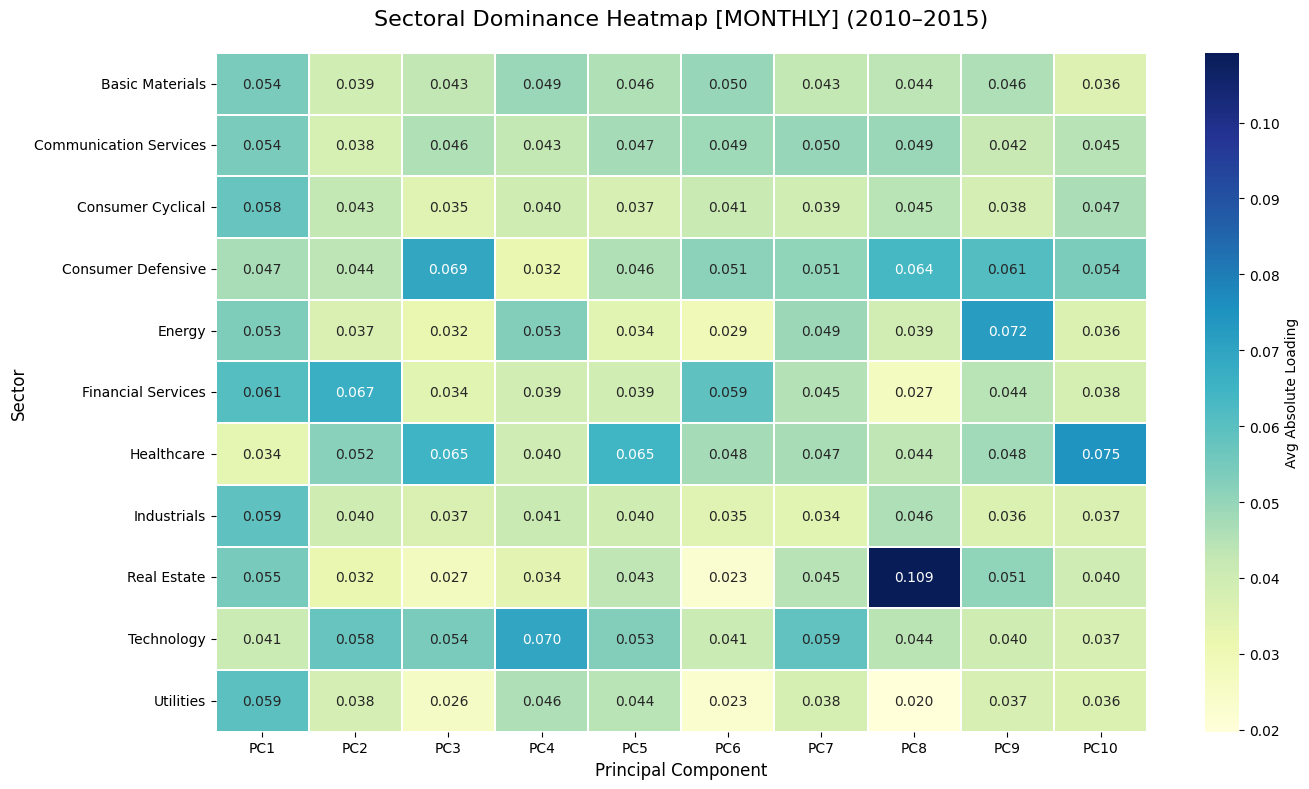


Multi-Frequency Analysis Complete for 2010–2015.


In [55]:
run_pca_analysis(2010, 2015)

## Analysis 2015 - 2020


MULTI-FREQUENCY PCA ANALYSIS: 2015 – 2020


############################################# DAILY ANALYSIS #############################################

[1] DATASET STRUCTURE (DAILY):
Total Rows (Trading Periods): 1556
Total Columns (Stocks):       317
Full Data Shape: (1556, 317)


,3MINDIA.NS,ABB.NS,ACC.NS,ABAN.NS,ADANIENT.NS,ADOR.NS,AKSHOPTFBR.NS,AKZOINDIA.NS,ALEMBICLTD.NS,ALFA.ST,...,M&M.NS,MRPL.NS,NAGAFERT.NS,ONGC.NS,PGHH.NS,RCF.NS,SCI.NS,STCINDIA.NS,TFCILTD.NS,ZENSARTECH.NS
Date,,,,,,,,,,,,,,,,,,,,,
2015-01-01,0.399772,0.284805,0.108523,0.913958,0.203047,-0.562764,0.533338,-0.076697,1.970691,-0.031566,...,0.059182,0.652211,0.007339,0.360743,0.136621,0.283078,1.210906,0.995235,0.165248,0.039515
2015-01-02,-0.128876,-0.343933,0.847886,-0.233072,0.120440,0.226023,0.727314,1.259316,0.121236,-0.317560,...,-0.421506,0.483053,0.007339,0.687160,0.243722,-0.207953,-0.306829,-0.506169,0.789500,0.236134
2015-01-05,-0.081401,-0.021924,0.147449,0.171115,0.261262,-0.199483,-0.044051,0.116419,0.191206,-0.595531,...,-0.139543,0.140910,0.007339,0.295964,-0.029883,-0.378661,0.071305,0.048957,-0.077944,-0.235278
2015-01-06,-1.271412,-0.304197,-1.992266,-1.742450,-0.263115,-0.639784,-1.965360,-1.510162,-0.985195,-0.031566,...,-0.244760,-1.401944,0.007339,-2.734687,-0.538615,-0.720977,-1.297133,-1.175424,-0.660363,-0.430912
2015-01-07,-0.354087,-0.468698,-0.672744,-1.435468,-0.302250,-0.158461,0.546978,0.207934,0.275518,-1.587833,...,0.381232,-0.573172,0.007339,0.675154,0.499492,0.691924,-0.248471,-0.232632,-0.386586,-0.060752



[2] TOP 10 EIGENVALUES & VARIANCE EXPLAINED (DAILY):


,Component,Eigenvalue ($\lambda$),\% Variance Explained,Cumulative Variance ($\%$)
0,PC1,50.608757,20.970936,20.970936
1,PC2,5.225559,2.165334,23.136270
2,PC3,3.836256,1.589643,24.725913
3,PC4,2.785242,1.154131,25.880045
4,PC5,2.445596,1.013390,26.893435
5,PC6,2.034222,0.842928,27.736363
6,PC7,2.004740,0.830712,28.567074
7,PC8,1.937680,0.802923,29.369998
8,PC9,1.862536,0.771786,30.141784
9,PC10,1.772475,0.734467,30.876250



[3] VARIANCE THRESHOLD SUMMARY:


...


[4] EIGENVECTORS (LOADINGS) - TOP 10 PCs (First 10 Stocks shown):


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10
3MINDIA.NS,-0.027657,-0.049016,0.037082,-0.060187,0.024438,0.057683,-0.061875,0.027671,-0.013623,0.028702
ABB.NS,-0.029634,-0.008525,-0.044004,0.000269,0.021405,0.043569,0.021928,-0.003675,-0.053385,-0.019299
ACC.NS,-0.056430,-0.067058,0.042496,-0.041787,0.047471,0.053023,0.094487,-0.072456,0.087980,0.078227
ABAN.NS,-0.064959,0.052975,-0.031669,0.062274,0.049730,-0.018246,-0.059301,-0.004776,0.022320,0.025209
ADANIENT.NS,-0.048499,-0.019761,-0.008156,-0.010793,0.022049,0.069396,0.100565,0.119066,-0.068550,-0.035970
ADOR.NS,-0.063396,-0.025568,0.006621,-0.007458,0.021181,-0.083163,0.015422,0.019462,0.092411,-0.021160
AKSHOPTFBR.NS,-0.077027,0.046154,-0.022877,0.106381,-0.002314,-0.066653,-0.060268,0.003117,-0.073525,-0.011185
AKZOINDIA.NS,-0.025631,-0.022086,-0.010958,-0.132810,-0.052417,0.060355,-0.060154,0.004467,0.000485,-0.101348
ALEMBICLTD.NS,-0.060575,0.049886,0.045998,0.017340,-0.000316,-0.012489,-0.008544,-0.053128,0.014003,0.008084
ALFA.ST,-0.050435,-0.045511,-0.006963,0.027779,0.118787,-0.004563,0.035529,0.061146,-0.092347,-0.005243



[5] EIGENVECTOR SUMMARY STATISTICS (TOP 10 PCs):


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10
mean,-0.053395,-0.000528,0.006365,-0.001104,0.002194,0.003672,0.000522,0.000330,0.002412,-0.000685
std,0.017451,0.056252,0.055892,0.056244,0.056211,0.056134,0.056252,0.056253,0.056203,0.056250
min,-0.097555,-0.155646,-0.128021,-0.142287,-0.142782,-0.166260,-0.152896,-0.161545,-0.143974,-0.209743
max,-0.003339,0.229395,0.234328,0.291196,0.163048,0.146828,0.231269,0.153160,0.193914,0.143651



[6] DOMINANT SECTORS (TOP 3 PCs):
 - PC1: Utilities                 | Avg Abs Loading: 0.0652
 - PC2: Consumer Cyclical         | Avg Abs Loading: 0.0592
 - PC3: Healthcare                | Avg Abs Loading: 0.1067


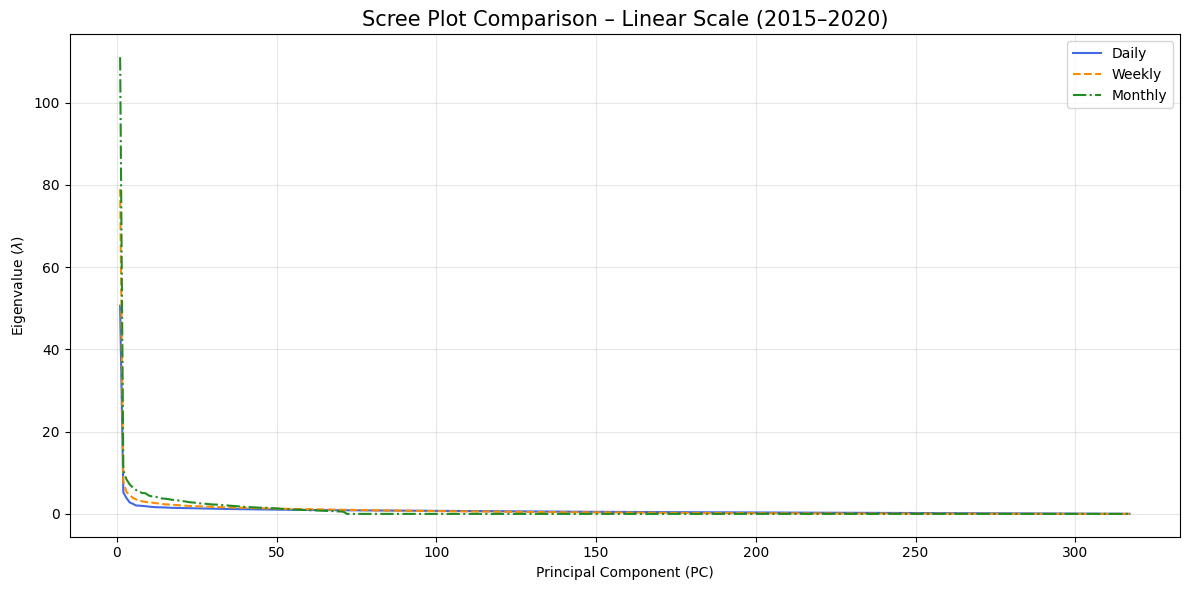

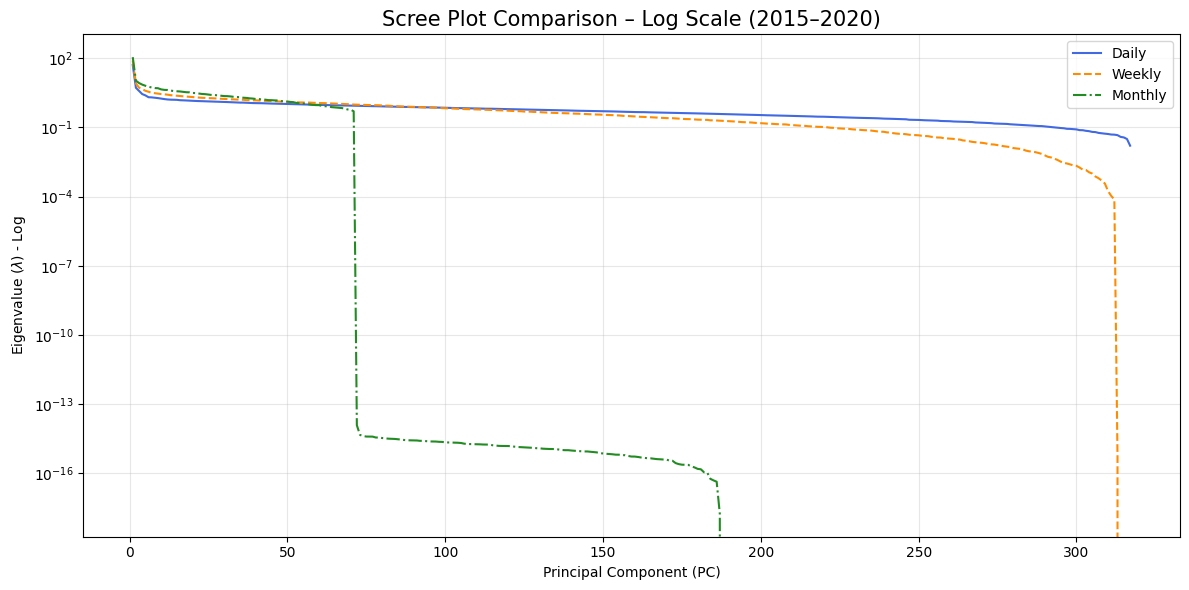

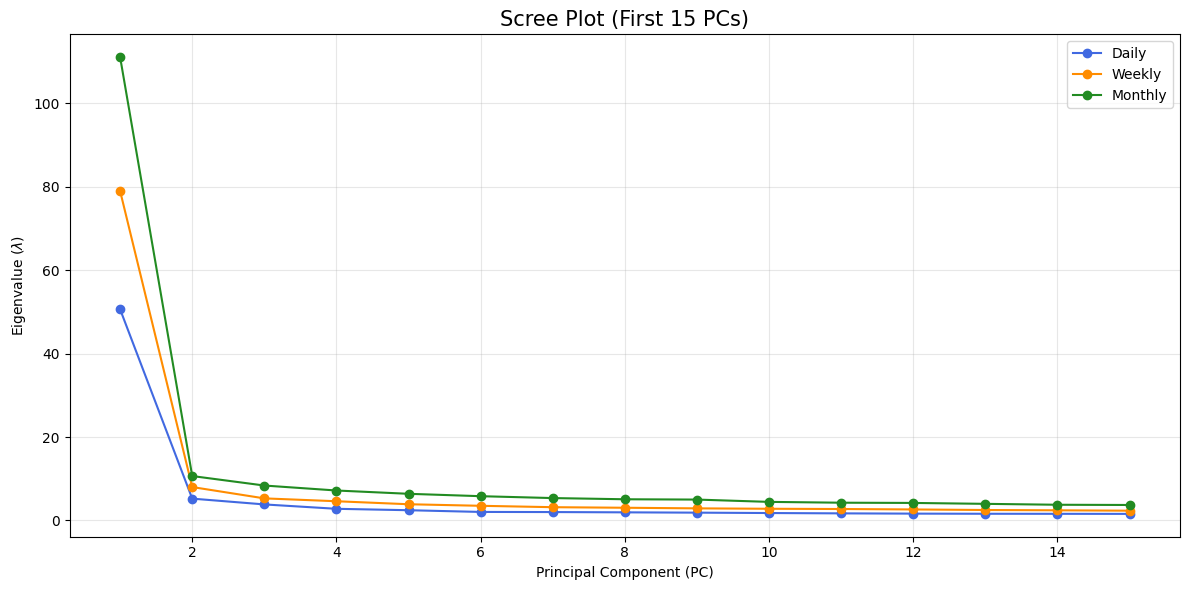

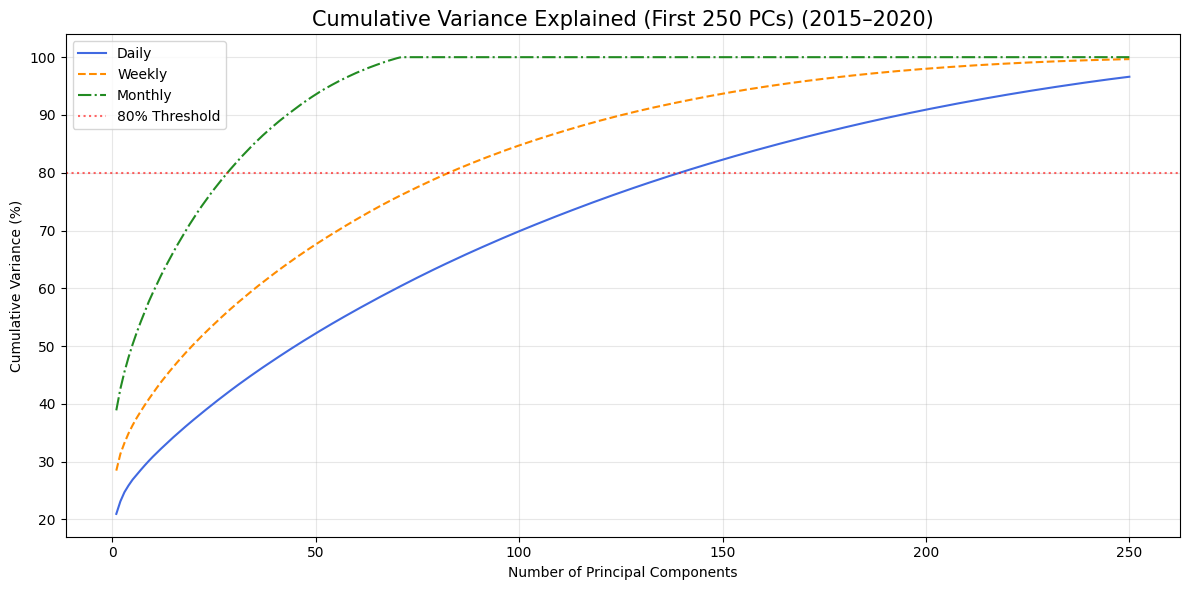

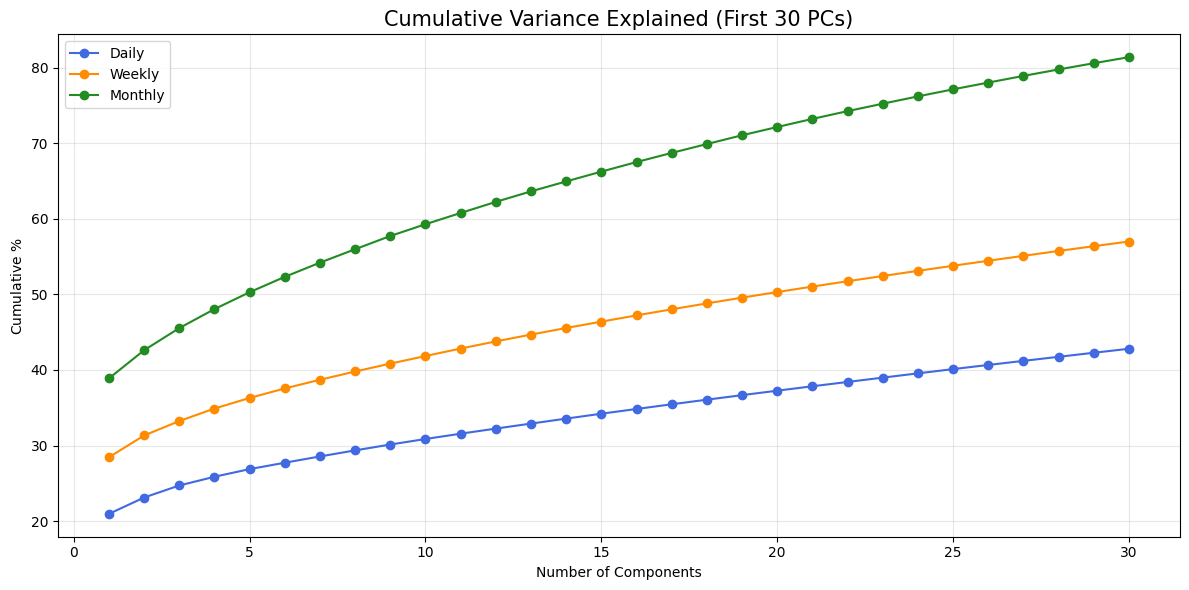

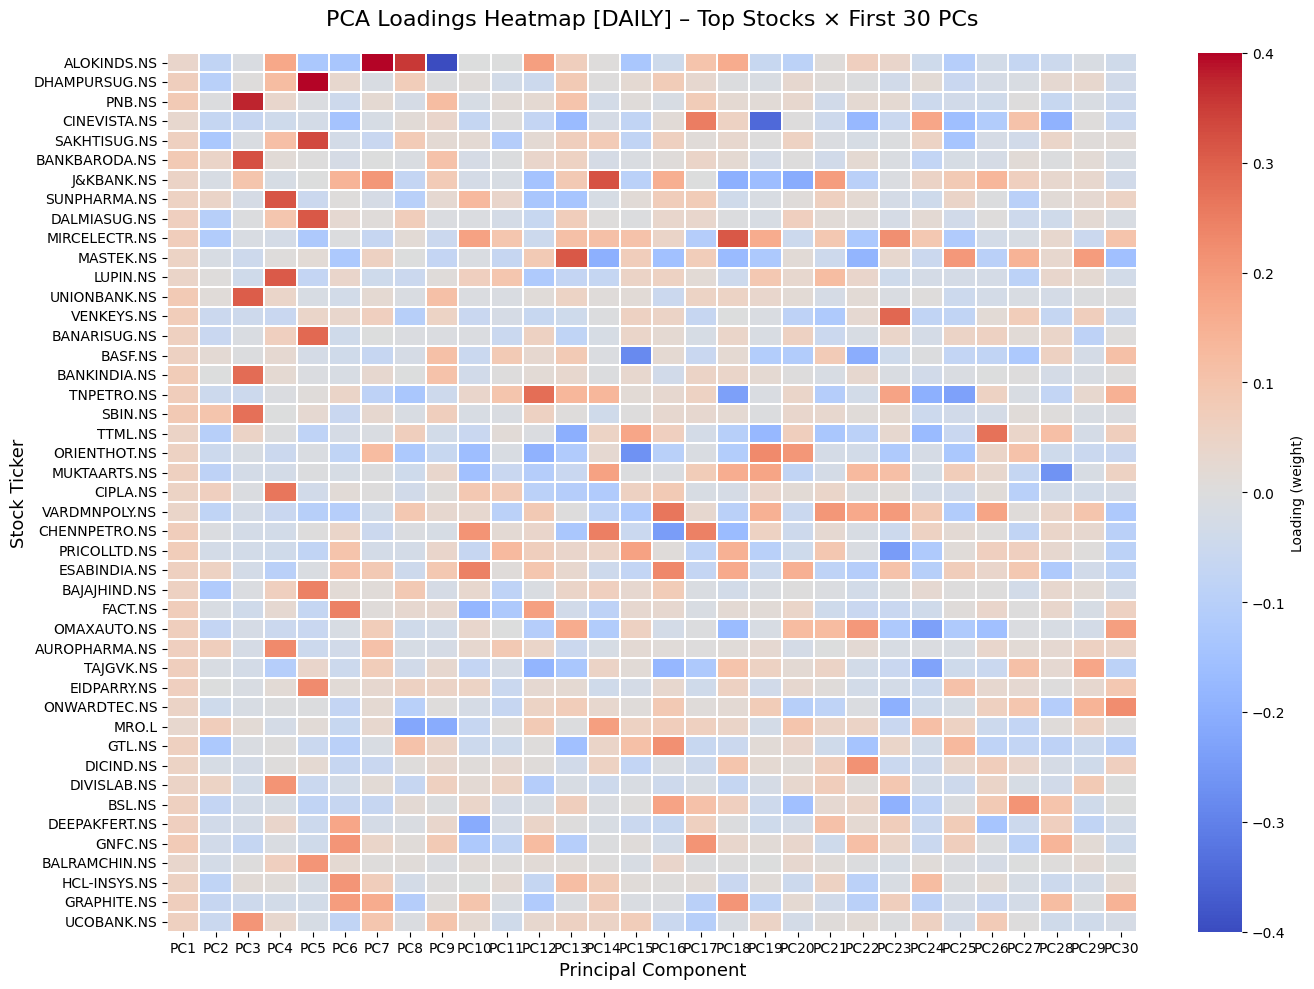

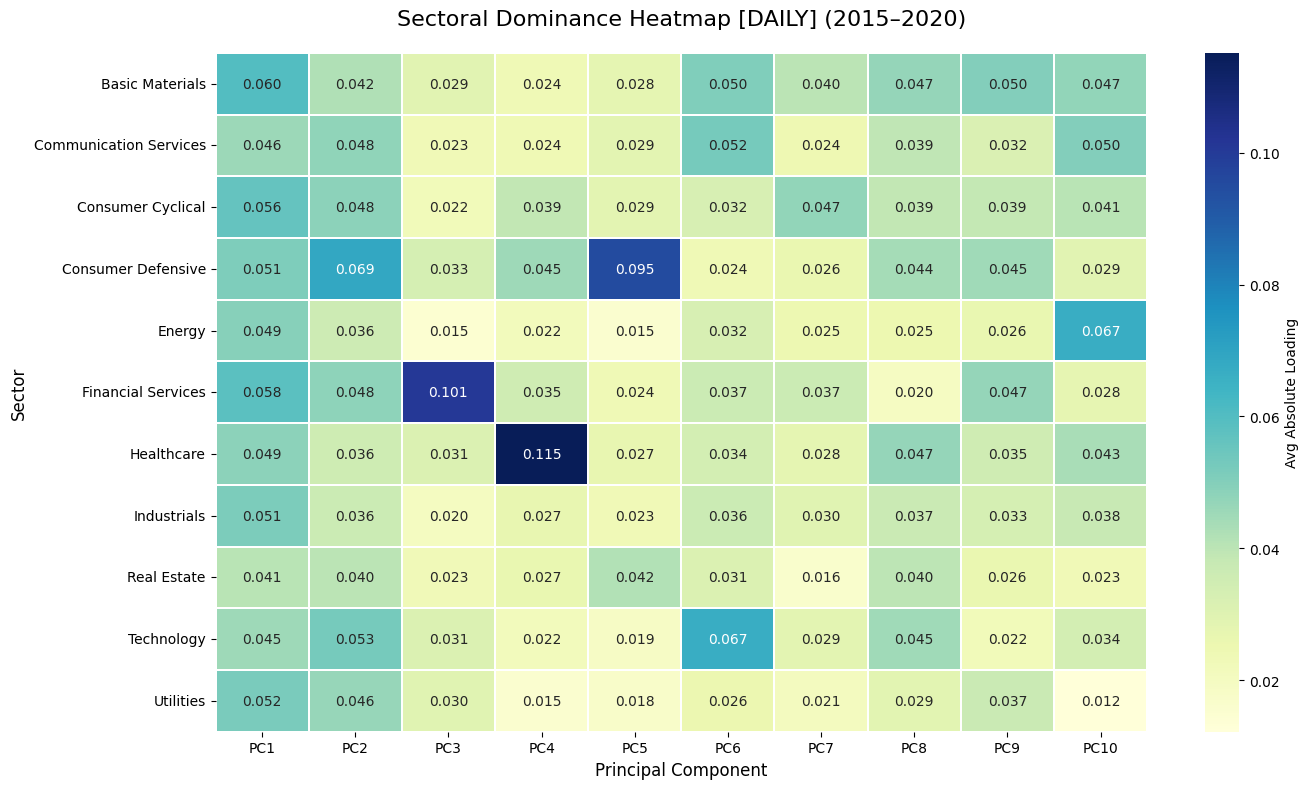

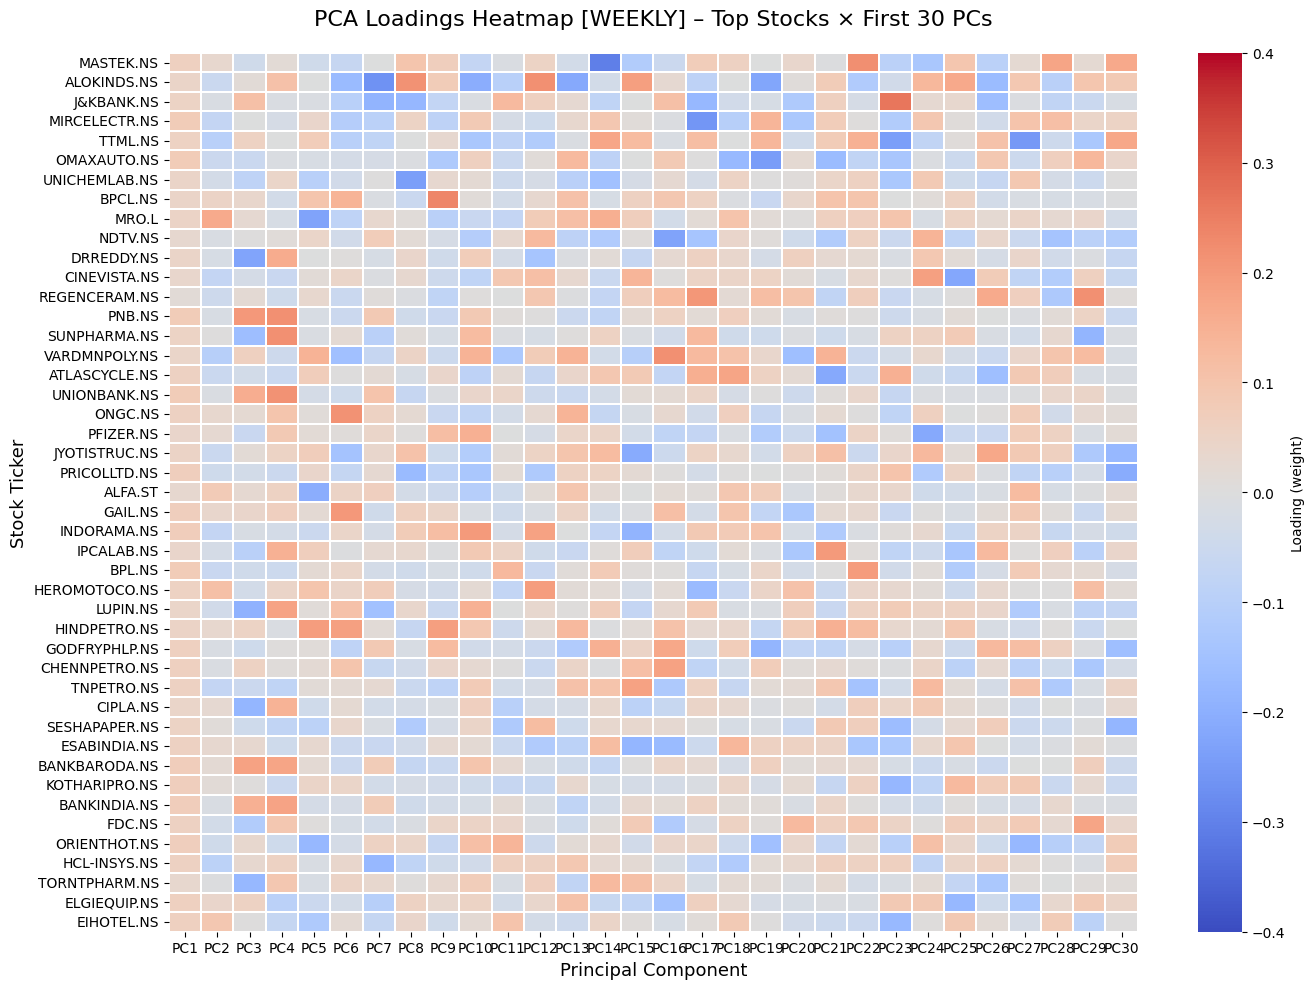

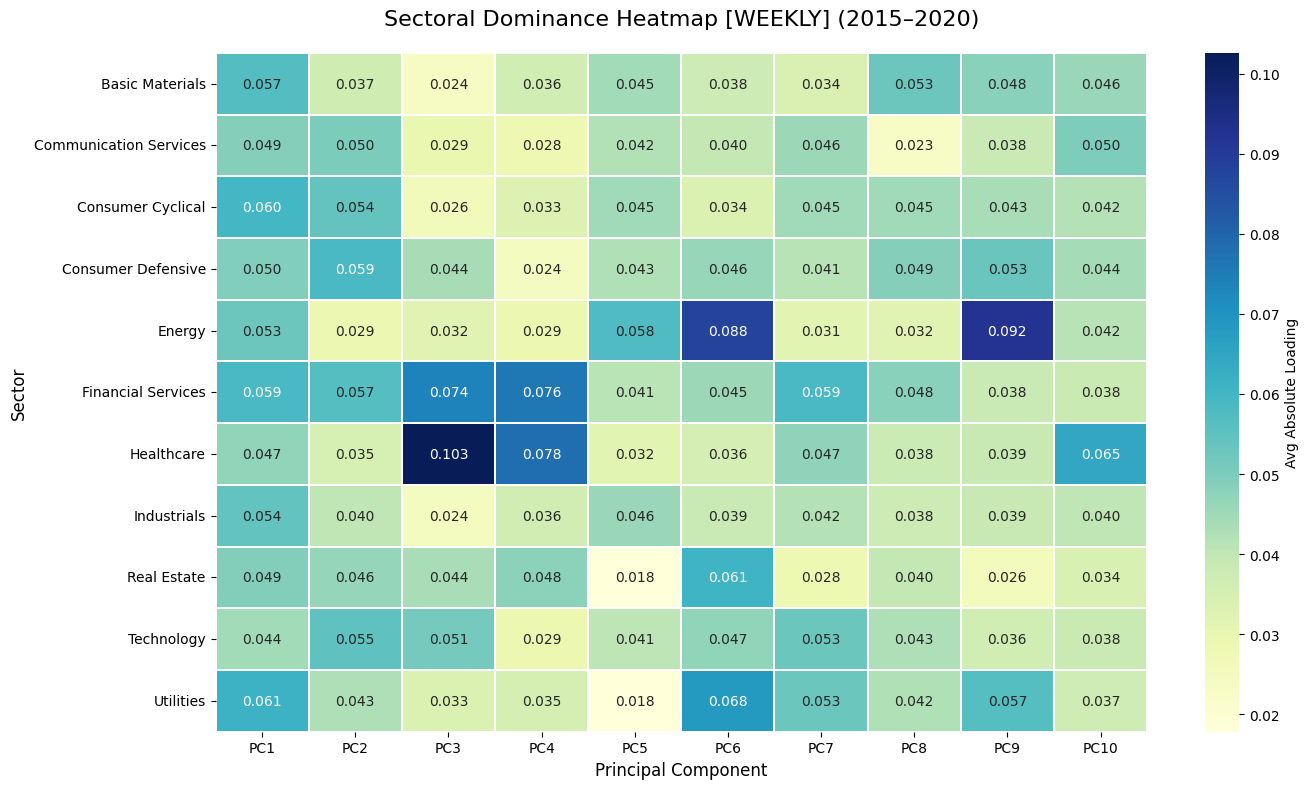

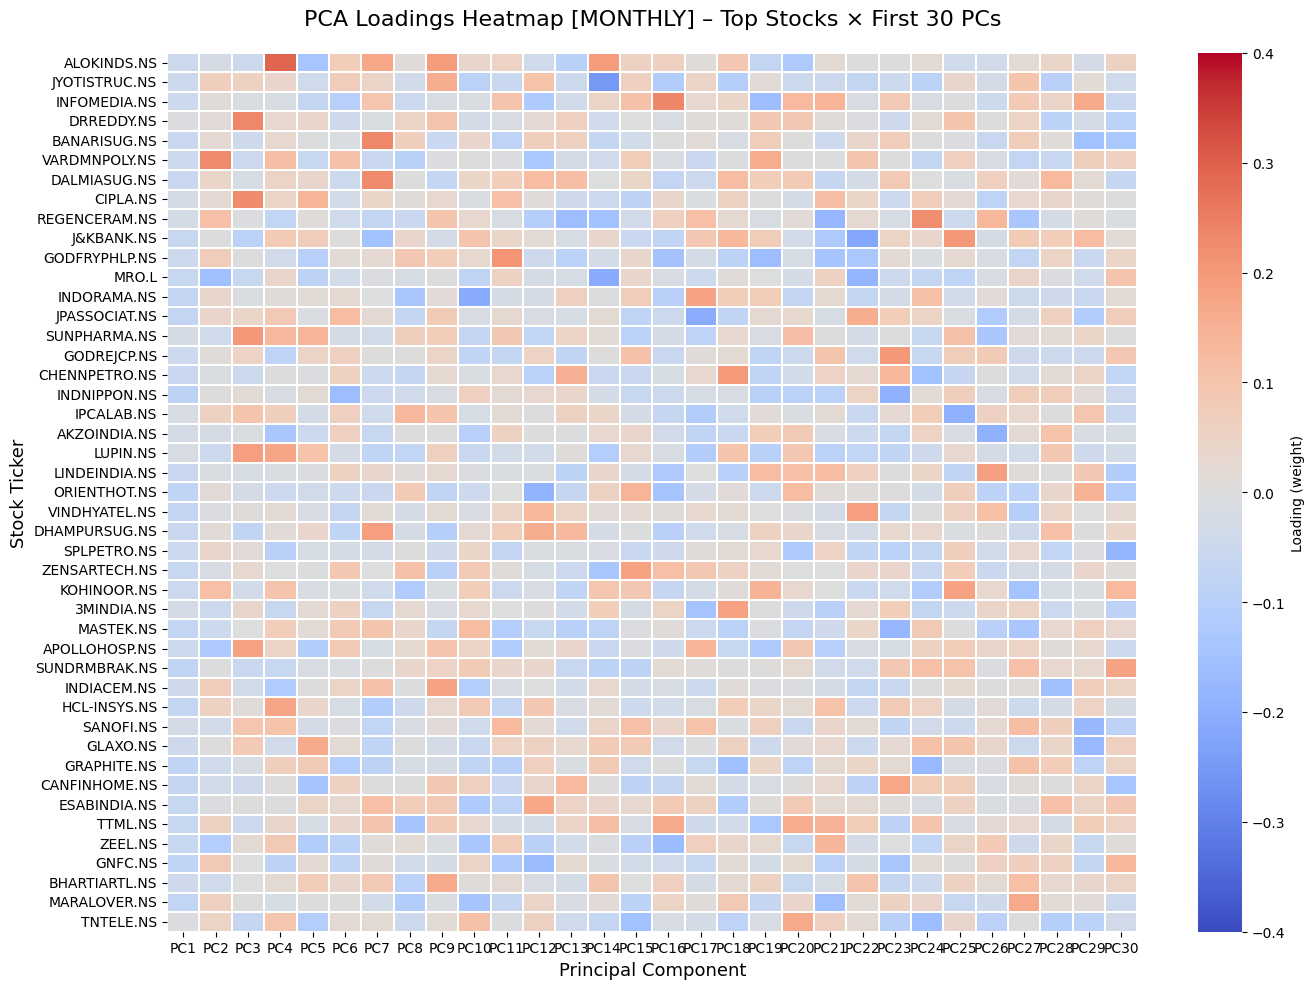

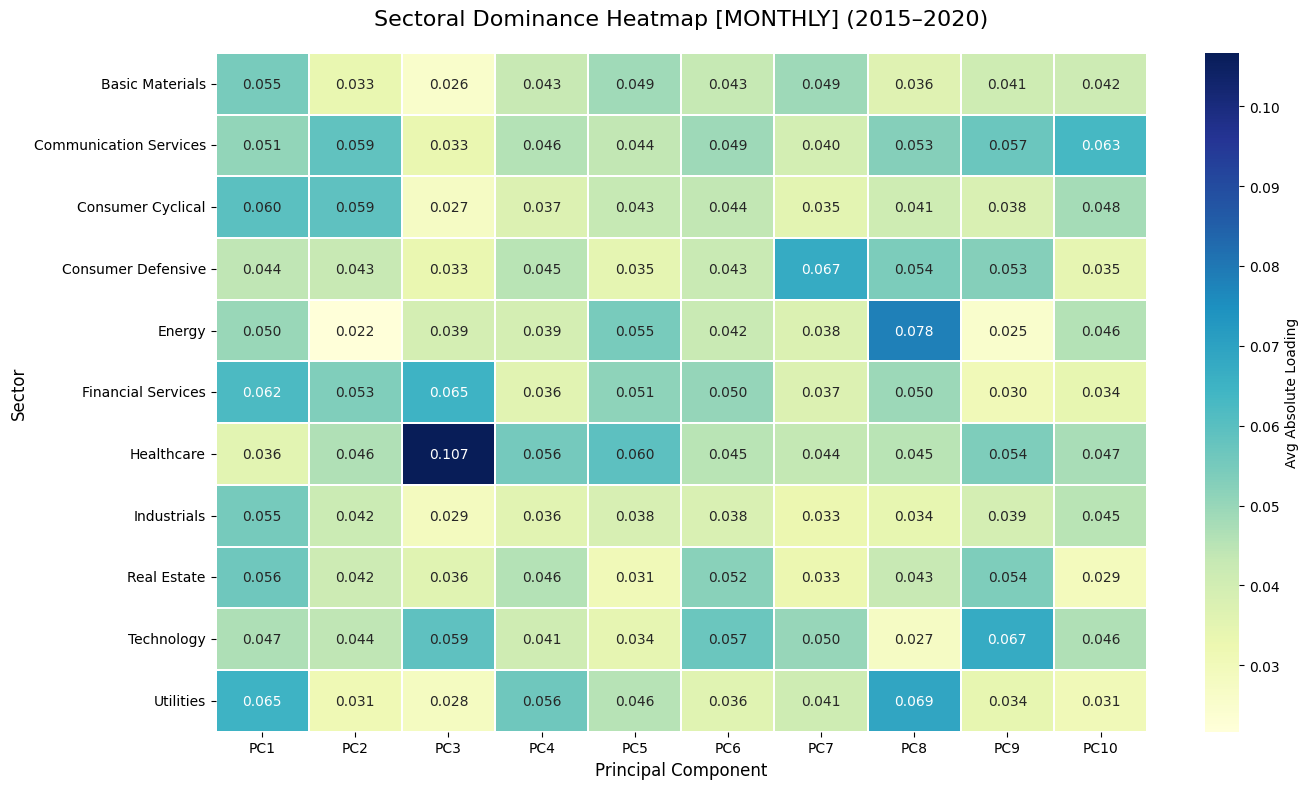


Multi-Frequency Analysis Complete for 2015–2020.


In [56]:
run_pca_analysis(2015, 2020)